# OPES MD data analysis for paper

## import

In [1]:
import numpy as np
import seaborn as sns
import os 
import sys
import pandas as pd
import mdtraj as md

from scipy.signal import savgol_filter

import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import ticker, cm

sys.path.append('scripts') #dirty way to import our script
from scripts.calcFES import calcFES, calcDeltaF, calcESS
from mlcolvar.utils.fes import compute_fes
from mlcolvar.utils.io import load_dataframe

In [2]:
def plot_FES_and_scatter(data, colvar, var1,var2, bin1=100, bin2=100, level_min = 0, level_max = 20, step_n = 20):
    bin1=bin1+1 
    bin2=bin2+1 
    alpha = np.array(data[var1]).reshape( bin1, bin2)
    comb_bonds = np.array(data[var2]).reshape( bin1, bin2)
    fes = np.array(data["file.free"]).reshape( bin1, bin2)
    fes = fes#*0.239006 #kJ to kkal
    #plot
    plt.contour(alpha, comb_bonds, fes, levels=np.linspace(level_min,level_max,step_n), linewidths=0.5, colors='k')
    cntr = plt.contourf(alpha, comb_bonds, fes, levels=range(level_min,level_max), cmap=cm.jet)
    
    # plt.scatter(x=colvar[var1],
    #             y=colvar[var2],
    #             s=0.5,
    #             alpha=0.05,
    #             c='k'
    #             # c=time
    #            )
    
    plt.colorbar(cntr, label="FES [kJ/mol]")
    # plt.xlim(0,15)
    # plt.ylim(1,20)
    plt.xlabel(var1)
    plt.ylabel(var2)
    
    # plt.show()

In [3]:
#plot-related stuff
import matplotlib.pyplot as plt
from IPython.display import clear_output

#set bigger font sizes
SMALL_SIZE = 8
MEDIUM_SIZE = 8
BIG_SIZE = 8
plt.rc('font', size=SMALL_SIZE)        # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)   # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)  # legend fontsize
plt.rc('figure', titlesize=BIG_SIZE)   # fontsize of the figure title

try:
# https://github.com/luigibonati/fessa-color-palette/blob/master/fessa.py
    import fessa
    plt.set_cmap('fessa')
except:
    pass # no big deal

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 8,

    # Axes
    "axes.titlesize": 8,
    "axes.labelsize": 8,

    # Tick labels
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    # Legend
    "legend.fontsize": 8,

    # Figure title
    "figure.titlesize": 8,

    # Colorbar (uses axes settings, but these help in some cases)
    "axes.titlepad": 6,
})

In [4]:
def plot_fes1D(grid, fes, max_fes=70, reference=False, **kwargs):
    if reference:
        plt.plot(FES1D.iloc[:,0], FES1D.iloc[:,1],':k')
        plt.xlim(-np.pi, np.pi)
        plt.xlabel(r'$\phi$')
    plt.plot(grid, fes, **kwargs)
    plt.ylim(0, max_fes)
    plt.ylabel(r'free energy [kJ/mol]')

def plot_deltaF(time, deltaF, reference=False, **kwargs):
    plt.plot(time, deltaF, **kwargs)
    if reference:
        plt.axhline(DF, ls=':', color='black')
        plt.axhspan(DF-1, DF+1, alpha=.1, color='black')
    plt.xlim(0, time[-1])
    plt.xlabel(r'time [ps]')
    plt.ylabel(r'$\Delta F$ [kJ/mol]')

In [5]:
#useful constants for our simulations
KB = 0.0083144621
T = 300
BETA = 1/(KB*T)
KBT = KB*T

cm2inch = 1/2.54

## Folding

### Read OneOPES data

In [6]:
colvar_list = []
path_folding = r'C:/Users/vacaa/Documents/REPORTS/170/data/Folding'


for j in range(1,5):
    colvar_rerun = load_dataframe(f'{path_folding}/One_OPES_{j}/0/COLVAR_RERUN')
    colvar_rerun['time']/= 10 #ns
    colvar = load_dataframe(f'{path_folding}/One_OPES_{j}/0/COLVAR.0')
    colvar['time'] = round(colvar['time']) #ns
    colvar['time']/= 1000 #ns
    colvar_rerun = colvar_rerun.merge(colvar, on="time", how="left")
    colvar_rerun['Repeat'] = [j]*len(colvar_rerun)
    colvar_list.append(colvar_rerun)

colvar_rerun = pd.concat(colvar_list)
colvar_rerun.replace(np.nan, 0, inplace=True)
colvar_rerun.columns

Index(['time', 'main_hel_sum_x', 'walker_x', 'opes1.bias', 'opes1.rct',
       'opes1.zed', 'opes1.neff', 'opes1.nker', 'ene', 'alpha', 'rg',
       'cmap_hel_sum', 'main_hel_sum_y', 'walker_y', 'Repeat'],
      dtype='str')

In [7]:
colvar_list = []
path_folding = r'C:/Users/vacaa/Documents/REPORTS/170/data/Folding'

for j in range(1,5):
    colvar = load_dataframe(f'{path_folding}/One_OPES_{j}/0/COLVAR.0')
    colvar_list.append(colvar)
    colvar['Replica'] = [1]*len(colvar)
    colvar['Repeat'] = [j]*len(colvar)
    

colvar = pd.concat(colvar_list)
colvar['time']/=1000
colvar.replace(np.nan, 0, inplace=True)

,time,opes1.bias,opes1.rct,opes1.zed,opes1.neff,opes1.nker,ene,alpha,rg,cmap_hel_sum,main_hel_sum,walker,Replica,Repeat
0,0.000000,-10.000000,-10.000000,1.00000,1.036288,0.0,-321632.96875,0.103051,1.128161,0.119460,1.398717,0,1,1
1,0.002000,-10.000000,-10.000000,1.00000,1.036288,0.0,-340540.96875,0.119546,1.134088,0.123696,1.459539,0,1,1
2,0.004000,-10.000000,-10.000000,1.00000,1.036288,0.0,-342017.68750,0.102725,1.131132,0.115261,1.358563,0,1,1
3,0.006000,-10.000000,-10.000000,1.00000,1.036288,0.0,-341862.87500,0.098799,1.142624,0.107029,1.236291,0,1,1
4,0.008000,-10.000000,-10.000000,1.00000,1.036288,0.0,-341402.71875,0.105283,1.126783,0.115020,1.340199,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249996,499.992024,-6.252271,-2.228272,0.00318,223.940286,993.0,-340503.87500,7.424361,1.150844,0.605732,7.886670,0,1,4
249997,499.994024,-4.172596,-2.228272,0.00318,223.940286,993.0,-341289.15625,7.397723,1.150738,0.602127,7.824002,0,1,4
249998,499.996024,-5.680115,-2.228272,0.00318,223.940286,993.0,-341665.53125,7.429647,1.151286,0.598422,7.815407,0,1,4
249999,499.998024,-5.240503,-2.228272,0.00318,223.940286,993.0,-341910.09375,7.314998,1.171170,0.597112,7.748202,0,1,4


### Read conventional MD data

In [8]:
path_folding = r'C:/Users/vacaa/Documents/REPORTS/170/data/Folding'

colvar_conv = load_dataframe(f'{path_folding}/FCP1/plumed/COLVAR_RERUN')
colvar_conv['time']/= 20 #ns
colvar_conv["Time (us)"] = colvar_conv['time'] / 1000

colvar_conv.columns
colvar_conv

,time,alpha,rg,main_hel_sum,walker,Time (us)
0,0.00,0.117726,1.135078,1.593096,0,0.00000
1,0.05,0.107803,1.225108,1.459292,0,0.00005
2,0.10,0.097569,1.202006,1.363528,0,0.00010
3,0.15,0.115282,1.182579,1.541436,0,0.00015
4,0.20,0.109687,1.122113,1.436038,0,0.00020
...,...,...,...,...,...,...
199996,9999.80,8.516602,0.843321,8.716385,0,9.99980
199997,9999.85,8.575559,0.835933,8.803562,0,9.99985
199998,9999.90,8.466319,0.865043,8.826114,0,9.99990
199999,9999.95,8.614503,0.858353,8.990692,0,9.99995


### Plot Rg, alpha dynamics conventional MD

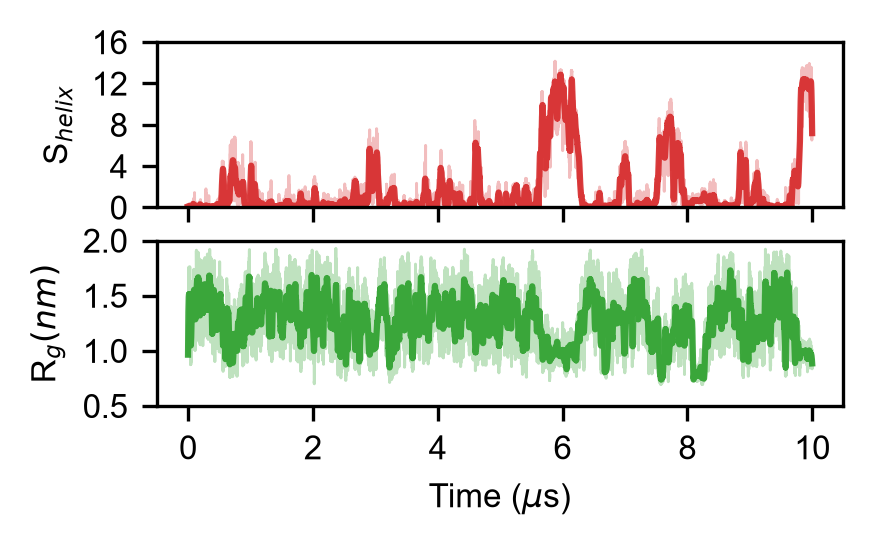

In [9]:
window_length = 701   # Must be odd
polyorder = 3

fig, axes= plt.subplots(2,1,
    figsize=(7.5*cm2inch,4*cm2inch),
    dpi=300,
    sharex = True
)


for ax, col, color in zip(axes, ["alpha", "rg"], ['tab:red','tab:green']):
    # Raw data
    ax.plot(
    colvar_conv["Time (us)"],
    colvar_conv[col],
    color=color,
    alpha=0.3,
    lw=0.7,
    )

    # Savitzky-Golay filtered data
    y_smooth = savgol_filter(
        colvar_conv[col],
        window_length=window_length,
        polyorder=polyorder
    )
    ax.plot(
            colvar_conv["Time (us)"],
            y_smooth,
            color=color,
            alpha=0.9,
            lw=1.5,
            label=col
        )
    

axes[1].set_xlabel(r"Time ($\mu$s)")
axes[0].set_ylabel("S$_{helix}$")
axes[1].set_ylabel("R$_{g} (nm)$")

axes[0].set_ylim(0,16)
axes[1].set_ylim(0.5,2.0)
axes[0].set_yticks(np.arange(0, 17, 4))
axes[1].set_yticks(np.arange(0.5, 2.1, 0.5))


plt.savefig('images/Alpha_Rg_time_conventional.png', dpi = 600, bbox_inches="tight",)




Text(0.5, 0, 'R$_{g} (nm)$')

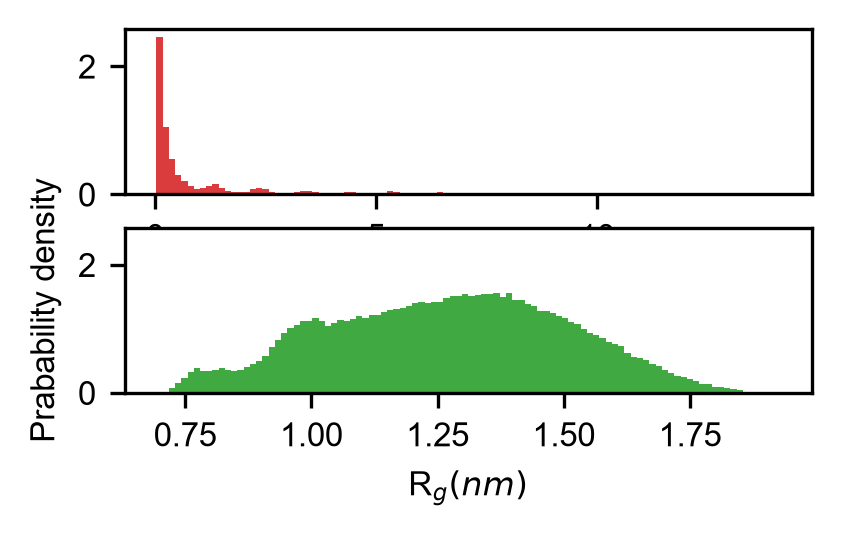

In [11]:
window_length = 701   # Must be odd
polyorder = 3

fig, axes= plt.subplots(2,1,
    figsize=(7.5*cm2inch,4*cm2inch),
    dpi=300,
    sharey = True
)


for ax, col, color in zip(axes, ["alpha", "rg"], ['tab:red','tab:green']):
    # Raw data
    # ax.plot(
    # colvar_conv["Time (us)"],
    # colvar_conv[col],
    # color=color,
    # alpha=0.3,
    # lw=0.7,
    # )

    ax.hist(
            colvar_conv[col],
            color=color,
            density=True,
            alpha=0.9,
            bins = 100,
            label=col
        )
    

axes[1].set_ylabel(r"Prabability density")
axes[1].set_ylabel(r"Prabability density")
axes[0].set_xlabel("S$_{helix}$")
axes[1].set_xlabel("R$_{g} (nm)$")

# axes[0].set_ylim(0,16)
# axes[1].set_ylim(0.5,2.0)
# axes[0].set_yticks(np.arange(0, 17, 4))
# axes[1].set_yticks(np.arange(0.5, 2.1, 0.5))


# plt.savefig('images/Alpha_Rg_hist_conventional.png', dpi = 600, bbox_inches="tight",)




### Plot 2D FES Rg/alpha conventional MD

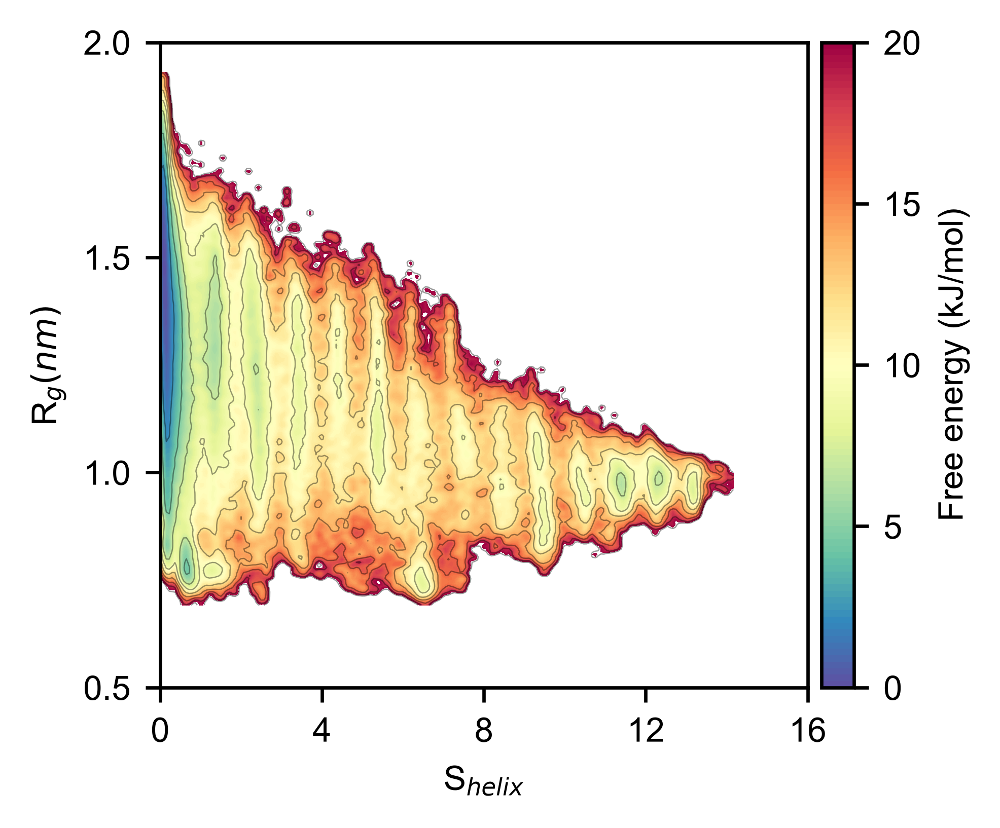

In [83]:
window_length = 701   # Must be odd
polyorder = 3

fig, ax= plt.subplots(1,1,
    figsize=(7.5*cm2inch,7*cm2inch),
    dpi=600,
    sharex = True
)

cv1 = colvar_conv["alpha"].to_numpy()
cv2 = colvar_conv["rg"].to_numpy()

cv = np.vstack([cv1, cv2])

fes, grid, bounds, error = compute_fes(
    cv.T,
    weights=None,
    blocks=1,
    kbt=KBT,
    bandwidth=0.005,
    scale_by="range",
    plot=False,
    plot_max_fes=100,
    eps=1e-10,
    backend="KDEpy",
)


extent = [item for sublist in bounds for item in sublist]


pp = ax.contourf(
    fes,
    extent=extent,
    levels=np.linspace(0, 20,101),
    cmap="Spectral_r"
)


# contour lines
ax.contour(
    fes,
    extent=extent,
    levels=np.linspace(0, 21, 10),
    colors="black",
    linewidths=0.3,
    alpha=0.4
)
    

ax.set_xlabel("S$_{helix}$")
ax.set_ylabel("R$_{g} (nm)$")

ax.set_xlim(0,16)
ax.set_ylim(0.5,2.0)
ax.set_xticks(np.arange(0, 17, 4))
ax.set_yticks(np.arange(0.5, 2.1, 0.5))

# Colorbar
cbar = fig.colorbar(
    pp,
    ax=ax,
    pad=0.02,
    fraction=0.05
)

cbar.set_label("Free energy (kJ/mol)")

# Optional: set colorbar ticks
cbar.set_ticks(np.arange(0, 21, 5))


plt.savefig('images/2DFES_Alpha_Rg_conventional.png', dpi = 600, bbox_inches="tight",)




### Helical content and bias over the time

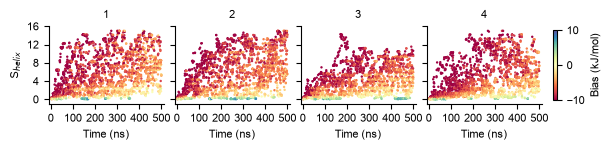

In [74]:
df = colvar[::100]
df = df[df["Replica"] == 1]

def scatter(data, **kwargs):
    plt.scatter(
        data["time"],
        data["alpha"],
        c=data["opes1.bias"],
        cmap="Spectral",
        norm=mpl.colors.Normalize(*(-10, 10)),   # same style as hue_norm=(-10,20)
        s=3,
        linewidths=0,
    )

g = sns.FacetGrid(
    df,
    col="Repeat",
    margin_titles=False,
    height=1,
    aspect=2,
)

g.map_dataframe(scatter)

# Shared colorbar
sm = mpl.cm.ScalarMappable(
    cmap="Spectral",
    norm=mpl.colors.Normalize(*(-10, 10))
)
sm.set_array([])

g.fig.colorbar(
    sm,
    ax=g.axes,
    label="Bias (kJ/mol)",
    pad=0.02,
    shrink=0.9,
)
g.set(
    xlim=(-10, 510),
    ylim=(-1, 16),
)
# More ticks
for ax in g.axes.flat:
    ax.set_xticks(np.arange(0, 501, 100))
    ax.set_yticks(np.arange(0, 17, 4))

g.set_titles(template="{col_name}", size=8)
g.fig.set_size_inches(16*cm2inch, 5*cm2inch)

g.set_axis_labels("Time (ns)", "S$_{helix}$")

plt.savefig('images/Alpha_time_hue_bias.png', dpi = 600, bbox_inches="tight",)

plt.show()

### Helical content FES

<>:121: SyntaxWarning: invalid escape sequence '\D'
<>:121: SyntaxWarning: invalid escape sequence '\D'
C:\Users\vacaa\AppData\Local\Temp\ipykernel_26692\1230047815.py:121: SyntaxWarning: invalid escape sequence '\D'
  ax.set_ylabel("$\Delta F$ (kJ/mol)")


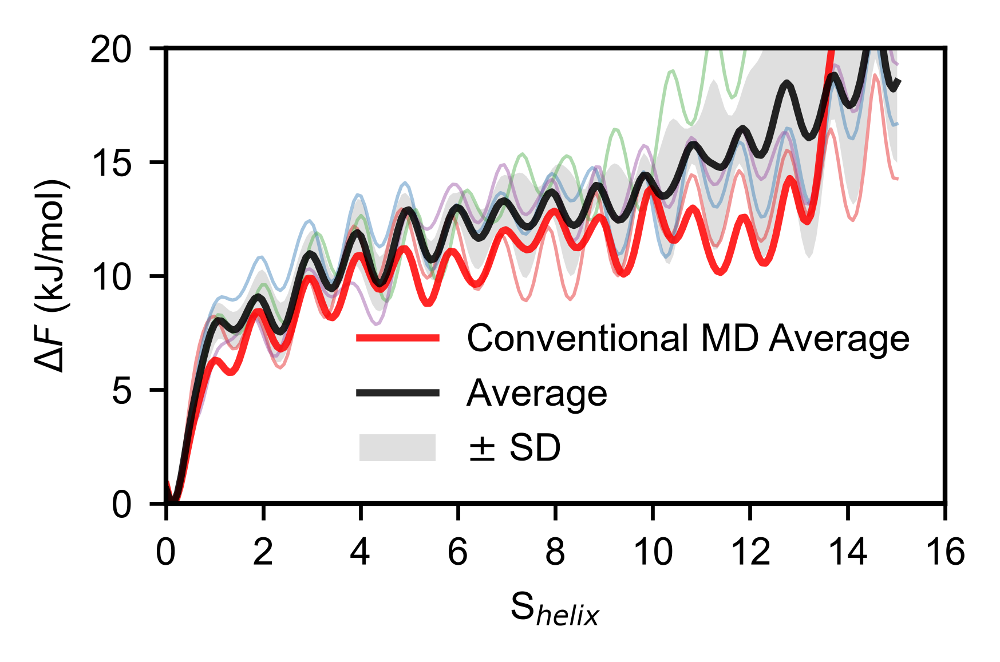

In [68]:
df = colvar[::1]
df = df[df['time']>0]
# df = df[df["Replica"] == 1]

T = 300
BETA = 1/(KB*T)

fes_list = []
grid_list = []

# Calculate FES for each repeat
for i in range(4):

    data = df[df["Repeat"] == i+1]

    bias = data["opes1.bias"].to_numpy()
    cv = data["alpha"].to_numpy()

    # numerically stable weights
    logweights = BETA * (bias - np.max(bias))
    w = np.exp(logweights)

    fes, grid, bounds, error = compute_fes(
        cv,
        weights=w,
        kbt = KB*T,
        blocks=1,
        bandwidth=0.01,
        scale_by="range",
        plot=False,
        plot_max_fes=100,
        eps=1e-10,
    )

    # normalize minimum to zero
    fes = fes - np.min(fes)

    fes_list.append(fes)
    grid_list.append(grid)


# Caluclate FES for conventional MD
cv = colvar_conv["alpha"].to_numpy()

fes_conv, grid_conv, bounds, error = compute_fes(
    cv,
    weights=None,
    kbt=KB*T,
    blocks=1,
    bandwidth=0.01,
    scale_by="range",
    plot=False,
    plot_max_fes=100,
    eps=1e-10,
)

# Convert to arrays
fes_array = np.array(fes_list)
grid = grid_list[0]

# Mean and standard deviation
fes_mean = np.mean(fes_array, axis=0)
fes_std = np.std(fes_array, axis=0)


# ----------------------------
# Publication quality plotting
# ----------------------------

fig, ax = plt.subplots(
    figsize=(7.5*cm2inch, 5*cm2inch),
    dpi=600
)

colors = plt.cm.Set1(range(4))

# Individual repeats
for i, fes in enumerate(fes_array):
    ax.plot(
        grid,
        fes,
        color=colors[i],
        lw=0.7,
        alpha=0.45,
        # label=f"Repeat {i+1}"
    )

# Conventional MD FES
ax.plot(
    grid_conv,
    fes_conv,
    color="red",
    lw=1.5,
    alpha=0.85,
    label="Conventional MD Average"
)

# Average FES
ax.plot(
    grid,
    fes_mean,
    color="black",
    lw=1.5,
    alpha=0.85,
    label="Average"
)

# Standard deviation envelope
ax.fill_between(
    grid,
    fes_mean - fes_std,
    fes_mean + fes_std,
    color="gray",
    alpha=0.25,
    linewidth=0,
    label=r"$\pm$ SD"
)

# Axis, axis labels and style
ax.set_xlabel("S$_{helix}$")
ax.set_ylabel("$\Delta F$ (kJ/mol)")

ax.set_xlim(0, 16)
ax.set_ylim(0, 20)
ax.set_xticks(np.arange(0, 17, 2))
ax.set_yticks(np.arange(0, 21, 5))


ax.legend(
    frameon=False,
)

for spine in ax.spines.values():
    spine.set_linewidth(1)

plt.tight_layout()
plt.savefig('images/Alpha_FES_v2.png', dpi = 600)
plt.show()

### Main helixes

<>:123: SyntaxWarning: invalid escape sequence '\D'
<>:123: SyntaxWarning: invalid escape sequence '\D'
C:\Users\vacaa\AppData\Local\Temp\ipykernel_24624\3753509571.py:123: SyntaxWarning: invalid escape sequence '\D'
  ax.set_ylabel("$\Delta F$ (kJ/mol)")


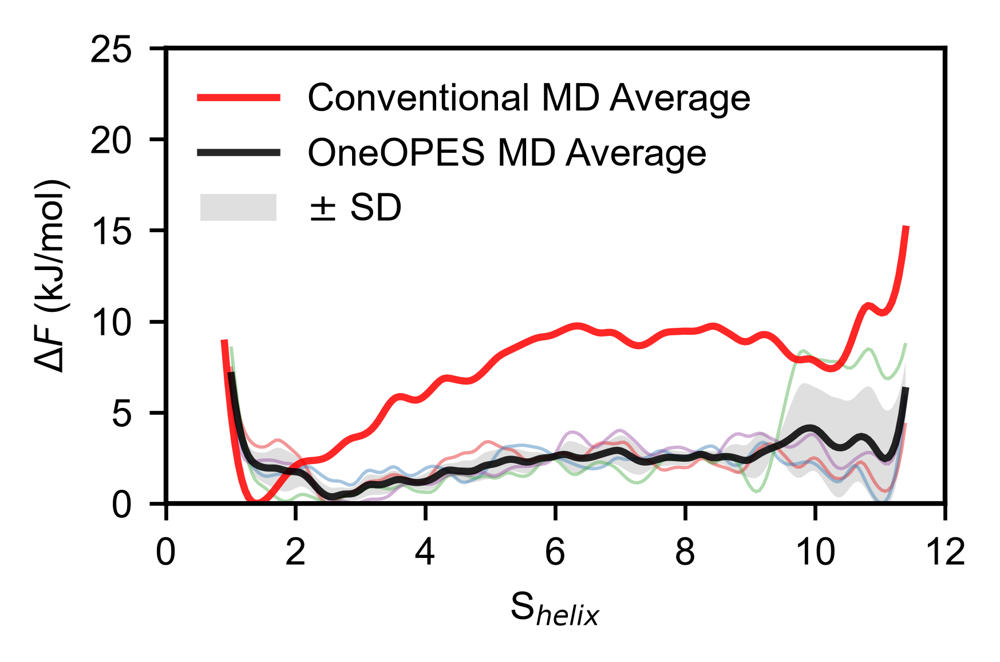

In [15]:
df = colvar_rerun[::1]
# df = df[df["Replica"] == 1]

T = 300
BETA = 1/(KB*T)

fes_list = []
grid_list = []

# Calculate FES for each repeat
for i in df["Repeat"].unique():

    data = df[df["Repeat"] == i]

    bias = data["opes1.bias"].to_numpy()
    cv = data["main_hel_sum_x"].to_numpy()

    # numerically stable weights
    logweights = BETA * (bias - np.max(bias))
    w = np.exp(logweights)

    fes, grid, bounds, error = compute_fes(
        cv,
        weights=None,
        blocks=1,
        kbt=KB*T,
        bandwidth=0.01,
        scale_by="range",
        plot=False,
        plot_max_fes=100,
        eps=1e-10,
    )

    # normalize minimum to zero
    fes = fes - np.min(fes)

    fes_list.append(fes)
    grid_list.append(grid)

# Caluclate FES for conventional MD
cv = colvar_conv["main_hel_sum"].to_numpy()

fes_conv, grid_conv, bounds, error = compute_fes(
    cv,
    weights=None,
    blocks=1,
    kbt=KB*T,
    bandwidth=0.01,
    scale_by="range",
    plot=False,
    plot_max_fes=100,
    eps=1e-10,
)

# normalize minimum to zero
fes_conv = fes_conv - np.min(fes_conv)


# Convert to arrays
fes_array = np.array(fes_list)
grid = grid_list[0]

# Mean and standard deviation
fes_mean = np.mean(fes_array, axis=0)
fes_std = np.std(fes_array, axis=0)


# ----------------------------
# Publication quality plotting
# ----------------------------

fig, ax = plt.subplots(
    figsize=(7.5*cm2inch, 5*cm2inch),
    dpi=600
)

colors = plt.cm.Set1(range(4))

# Individual repeats
for i, fes in enumerate(fes_array):
    ax.plot(
        grid,
        fes,
        color=colors[i],
        lw=0.7,
        alpha=0.45,
        # label=f"Repeat {i+1}"
    )

# Conventional MD FES
ax.plot(
    grid_conv,
    fes_conv,
    color="red",
    lw=1.5,
    alpha=0.85,
    label="Conventional MD Average"
)

# Average FES
ax.plot(
    grid,
    fes_mean,
    color="black",
    lw=1.5,
    alpha=0.85,
    label="OneOPES MD Average"
)

# Standard deviation envelope
ax.fill_between(
    grid,
    fes_mean - fes_std,
    fes_mean + fes_std,
    color="gray",
    alpha=0.25,
    linewidth=0,
    label=r"$\pm$ SD"
)

# Labels and style
ax.set_xlabel("S$_{helix}$")
ax.set_ylabel("$\Delta F$ (kJ/mol)")

ax.set_ylim(0, 25)
ax.set_xlim(0, 12)


ax.legend(
    frameon=False,
)

for spine in ax.spines.values():
    spine.set_linewidth(1)

plt.tight_layout()
plt.savefig('images/Main_hel_FES_well_tempered_v1.png', dpi = 600)
plt.show()

### Convergence plot selected CV

c:\Users\vacaa\Documents\REPORTS\170\Code\.venv\Lib\site-packages\numpy\_core\_methods.py:188: RuntimeWarning: invalid value encountered in subtract
  x = um.subtract(arr, arrmean, out=...)


Determined value: 9.404330002585233 ± 3.0145611002130424


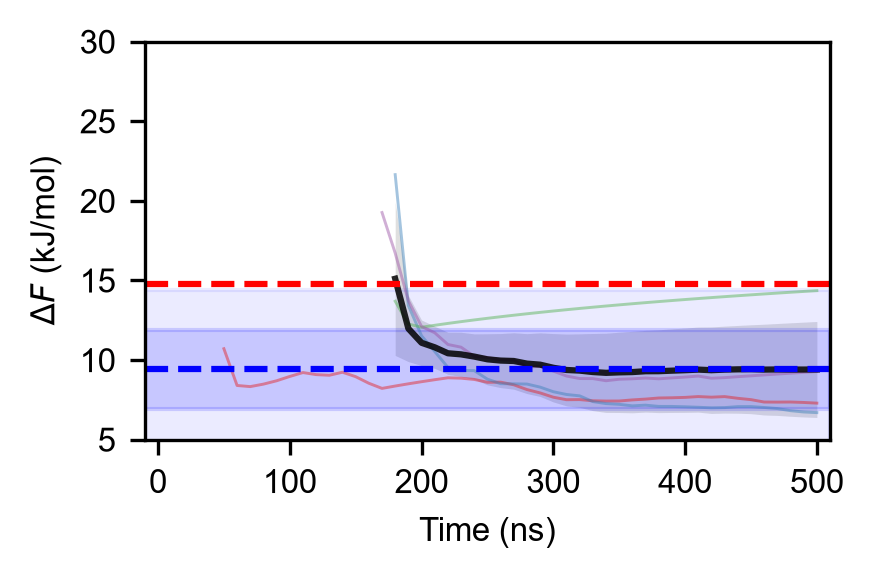

In [ ]:
fragments = 50
time_min = 0

df = colvar_rerun

T = 300
BETA = 1/(KB*T)

time_max = df["time"].max()

# Store convergence curves
deltaF_all = []
colors = plt.cm.Set1(np.arange(4))

for rep in range(1, 5):

    data_rep = df[df["Repeat"] == rep]

    deltaF_metad = np.empty(fragments)
    time_analyse = np.empty(fragments)

    for i in range(fragments):

        time_analyse[i] = (
            (time_max - time_min) / fragments * (i + 1)
            + time_min
        )

        data = data_rep[
            data_rep["time"].between(time_min, time_analyse[i])
        ]

        bias = data["opes1.bias"].to_numpy()
        cv = data["main_hel_sum_x"].to_numpy()

        # stable weights
        logweights = BETA * (bias - np.max(bias))
        w = np.exp(logweights)

        fes, grid, bounds, error = compute_fes(
            cv,
            weights=w,
            blocks=1,
            kbt=KB*T,
            bandwidth=0.01,
            scale_by="range",
            plot=False,
            plot_max_fes=50,
            eps=1e-10,
        )

        # Define basin
        mask = np.full(fes.shape, True)
        mask[grid > 11] = False

        deltaF_metad[i] = calcDeltaF(
            fes,
            basinMask=mask,
            kbt=KBT
        )

    deltaF_all.append(deltaF_metad)


# Convert to array
deltaF_all = np.array(deltaF_all)

# Average and standard deviation
deltaF_mean = np.mean(deltaF_all, axis=0)
deltaF_std = np.std(deltaF_all, axis=0)


# --------------------------
# Plot
# --------------------------

fig, ax = plt.subplots(
    figsize=(7.5*cm2inch,5*cm2inch),
    dpi=300
)



# Individual repeats
for i, deltaF in enumerate(deltaF_all):
    ax.plot(
        time_analyse,
        deltaF,
        color=colors[i],
        lw=0.7,
        alpha=0.45,
        # label=f"Repeat {i+1}"
    )
    
# Average
ax.plot(
    time_analyse,
    deltaF_mean,
    color="black",
    lw=1.5,
    alpha=0.85,
    label="Average"
)

# Standard deviation
ax.fill_between(
    time_analyse,
    deltaF_mean - deltaF_std,
    deltaF_mean + deltaF_std,
    color="gray",
    alpha=0.25,
    linewidth=0,
    label="± SD"
)
#Comventional MD
deltaF_final = 14.744542241094628
ax.axhline(
    deltaF_final,
    color="red",
    lw=1.5,
    linestyle="--",
    label=r"Conventional MD"
)

# Last values
deltaF_final = deltaF_mean[-1]
ax.axhline(
    deltaF_final,
    color="blue",
    lw=1.5,
    linestyle="--",
    label=r"OneOPES MD $\Delta F_{\mathrm{final}}$"
)

ax.axhspan(
    deltaF_final - KBT,
    deltaF_final + KBT,
    color="blue",
    alpha=0.15,
    label=r"$\Delta F_{\mathrm{final}}\pm k_BT$"
)

ax.axhspan(
    deltaF_final - 2*KBT,
    deltaF_final + 2*KBT,
    color="blue",
    alpha=0.08,
    label=r"$\Delta F_{\mathrm{final}}\pm 2k_BT$"
)

# Cosmetics
ax.set_xlabel("Time (ns)")
ax.set_ylabel(r"$\Delta F$ (kJ/mol)")


# ax.legend(
#     frameon=False,
#     loc = 'upper left',
#     # ncols = 2,
# )
plt.xlim(-10,510)
plt.ylim(5,30)




plt.tight_layout()
print(f'Determined value: {deltaF_final} ± {deltaF_std[-1]}')
plt.savefig('images/Convergence_main_hel_v2.png', dpi = 600)
plt.show()

In [12]:
KBT * np.log(0.5 * 10**(-6)), KBT * 0.1/0.5

(np.float64(-36.18950546664939), 0.49886772599999996)

### 2D alpha/rg FES

<>:129: SyntaxWarning: invalid escape sequence '\D'
<>:129: SyntaxWarning: invalid escape sequence '\D'
C:\Users\vacaa\AppData\Local\Temp\ipykernel_21432\3218920071.py:129: SyntaxWarning: invalid escape sequence '\D'
  "$\Delta F$ (kJ/mol)",


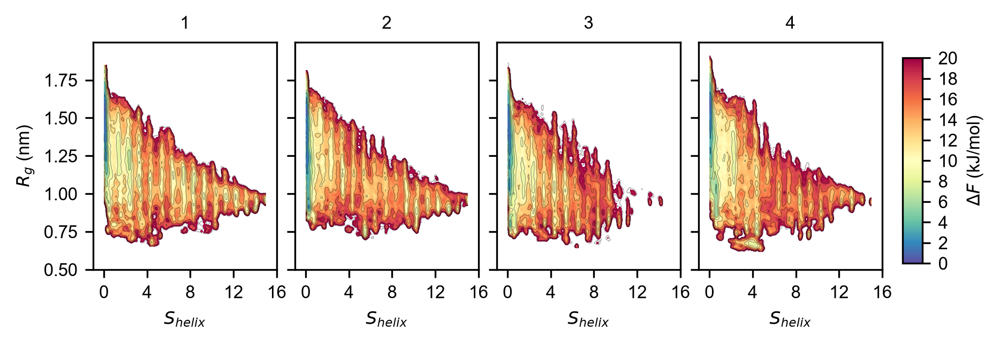

In [159]:
# -----------------------------
# Data preparation
# -----------------------------

df = colvar.copy()
df = df[df["Replica"] == 1]
df = df[df["time"] > 0]

var1 = "alpha"
var2 = "rg"

T = 300
BETA = 1/(KB*T)


# -----------------------------
# Figure setup
# -----------------------------

fig, axes = plt.subplots(
    1, 4,
    figsize=(16*cm2inch, 5*cm2inch),
    dpi=300,
    sharex=True,
    sharey=True
)

fig.subplots_adjust(
    left=0.08,
    right=0.86,
    bottom=0.18,
    top=0.90,
    wspace=0.1
)


pp = None


# -----------------------------
# Calculate and plot FES
# -----------------------------

for i, ax in enumerate(axes):

    data = df[df["Repeat"] == i+1]

    bias = data["opes1.bias"].to_numpy()

    cv1 = data[var1].to_numpy()
    cv2 = data[var2].to_numpy()

    cv = np.vstack([cv1, cv2])


    # weights
    logweights = BETA * (bias - np.max(bias))
    w = np.exp(logweights)
    w /= np.sum(w)


    fes, grid, bounds, error = compute_fes(
        cv.T,
        weights=w,
        blocks=1,
        kbt=KB*T,
        bandwidth=0.005,
        scale_by="range",
        plot=False,
        plot_max_fes=100,
        eps=1e-10,
        backend="KDEpy",
    )


    extent = [item for sublist in bounds for item in sublist]


    pp = ax.contourf(
        fes,
        extent=extent,
        levels=np.linspace(0, 20,101),
        cmap="Spectral_r"
    )


    # contour lines
    ax.contour(
        fes,
        extent=extent,
        levels=np.linspace(0, 21, 10),
        colors="black",
        linewidths=0.3,
        alpha=0.4
    )

    ax.set_title(f"{i+1}",)

    ax.set_xlabel(r"$S_{helix}$", )

    if i == 0:
        ax.set_ylabel(r"$R_g$ (nm)", )

    if i > 0:
        ax.tick_params(
            direction="out",
            top=False,
            left=True,
            right=False,
            # length=4,
            # width=1
        )


# -----------------------------
# Shared colorbar
# -----------------------------

cbar_ax = fig.add_axes([0.88, 0.20, 0.02, 0.65])

cbar = fig.colorbar(
    pp,
    cax=cbar_ax
)
cbar.set_ticks(np.linspace(0,20,11))


cbar.set_label(
    "$\Delta F$ (kJ/mol)",
)


# -----------------------------
# Axis limits
# -----------------------------

for ax in axes:
    ax.set_xlim(-1, 16)
    ax.set_ylim(0.5, 2.0)
    ax.set_xticks(np.arange(0, 17, 4))
    ax.set_yticks(np.arange(0.5, 2, 0.25))

# -----------------------------
# Save figure
# -----------------------------

plt.savefig(
    "images/2D_FES_alpha_Rg.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

### Analyse folding propensity of different residues

#### All conventinal data

<mdtraj.Trajectory with 200001 frames, 294 atoms, 21 residues, and unitcells>


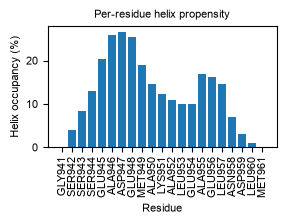

In [6]:
### Calcualte

traj = md.load(
    r"c:\Users\vacaa\Documents\REPORTS\170\data\Folding\FCP1\plumed\chainB.xtc",
    top=r"c:\Users\vacaa\Documents\REPORTS\170\data\Folding\FCP1\plumed\chainB.pdb"
)

print(traj)

dssp = md.compute_dssp(traj[::])
helix = np.isin(dssp, ["H", "G", "I"])
helix_probability = helix.mean(axis=0)

sheet = np.isin(dssp, ['E'])
sheet_probability = sheet.mean(axis=0)

top = traj.topology
residue_labels = [
    f"{res.name}{res.resSeq}"
    for res in top.residues
]

df = pd.DataFrame({
    "Residue": residue_labels,
    "Helix_Probability": helix_probability
})

df["Helix_%"] = 100 * df["Helix_Probability"]

### Plot
plt.figure(figsize=(7.5*cm2inch,4*cm2inch))

plt.bar(
    residue_labels,
    df["Helix_%"]
)

plt.xticks(rotation=90)

plt.ylabel("Helix occupancy (%)")
plt.xlabel("Residue")
plt.title("Per-residue helix propensity")

# plt.tight_layout()

# plt.savefig(
#     "images/Helix_propensity_conventional_MD.png",
#     dpi=600,
#     bbox_inches="tight"
# )

plt.show()

#### Block averaged conventinal data

<mdtraj.Trajectory with 200001 frames, 294 atoms, 21 residues, and unitcells>


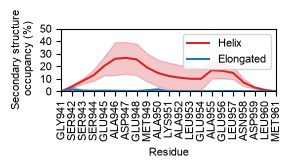

In [78]:
# =============================================================================
# Load trajectory
# =============================================================================
n_blocks = 5      # <----- Change this to any number

traj = md.load(
    r"c:\Users\vacaa\Documents\REPORTS\170\data\Folding\FCP1\plumed\chainB.xtc",
    top=r"c:\Users\vacaa\Documents\REPORTS\170\data\Folding\FCP1\plumed\chainB.pdb"
)

print(traj)

# =============================================================================
# Block averaging
# =============================================================================

dssp = md.compute_dssp(traj)
helix = np.isin(dssp, ["H", "G", "I"])

sheet = np.isin(dssp, ['E','B'])
sheet_probability = sheet.mean(axis=0)

# Split trajectory into blocks
helix_blocks = np.array_split(helix, n_blocks, axis=0)
sheet_blocks = np.array_split(sheet, n_blocks, axis=0)

# Compute helix propensity for each block
block_helix_propensities = np.array([
    block.mean(axis=0)
    for block in helix_blocks
])
block_sheet_propensities = np.array([
    block.mean(axis=0)
    for block in sheet_blocks
])


# Mean and SD across blocks
helix_probability = block_helix_propensities.mean(axis=0)
helix_sd = block_helix_propensities.std(axis=0, ddof=1)

sheet_probability = block_sheet_propensities.mean(axis=0)
sheet_sd = block_sheet_propensities.std(axis=0, ddof=1)

# =============================================================================
# Labels
# =============================================================================

top = traj.topology

residue_labels = [
    f"{res.name}{res.resSeq}"
    for res in top.residues
]

df = pd.DataFrame({
    "Residue": residue_labels,
    "Helix_%": 100 * helix_probability,
    "Helix_SD_%": 100 * helix_sd,
    "Sheet_%": 100 * sheet_probability,
    "Sheet_SD_%": 100 * sheet_sd
})

# =============================================================================
# Plot
# =============================================================================

x = np.arange(len(residue_labels))

plt.figure(figsize=(7.5 * cm2inch, 4 * cm2inch))

# Mean ± SD
plt.fill_between(
    x,
    df["Helix_%"] - df["Helix_SD_%"],
    df["Helix_%"] + df["Helix_SD_%"],
    color="tab:red",
    alpha=0.25
)

plt.plot(
    x,
    df["Helix_%"],
    color="tab:red",
    lw=1.5,
    label = 'Helix'
)
plt.fill_between(
    x,
    df["Sheet_%"] - df["Sheet_SD_%"],
    df["Sheet_%"] + df["Sheet_SD_%"],
    color="tab:blue",
    alpha=0.25
)

plt.plot(
    x,
    df["Sheet_%"],
    color="tab:blue",
    lw=1.5,
    label = 'Elongated'
)

plt.xticks(x, residue_labels, rotation=90)
plt.yticks(np.arange(0,51,10), )

plt.xlim(0, len(x)-1)
plt.ylim(0, 50)

plt.ylabel("Secondary structure\n occupancy (%)")
plt.xlabel("Residue")

plt.legend()

plt.tight_layout()

plt.savefig(
    "images/Helix_Sheet_propensity_conventional_MD_5blocks.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

#### Biased computation

In [14]:
BETA = 1/(KB*T)

# =============================================================================
# Paths
# =============================================================================

path_folding = r"C:/Users/vacaa/Documents/REPORTS/170/data/Folding"

# =============================================================================
# Conventional MD
# =============================================================================

traj = md.load(
    f"{path_folding}/FCP1/plumed/chainB.xtc",
    top=f"{path_folding}/FCP1/plumed/chainB.pdb"
)

dssp = md.compute_dssp(traj)
helix = np.isin(dssp, ["H", "G", "I"])
helix_probability_conv = helix.mean(axis=0)

# Residue labels
top = traj.topology
residue_labels = [
    f"{res.name}{res.resSeq}"
    for res in top.residues
]

# =============================================================================
# One-OPES trajectories
# =============================================================================

opes_probabilities = []

for j in range(1, 5):
    print(f"Processing One_OPES_{j}")

    traj = md.load(
        f"{path_folding}/One_OPES_{j}/0/md_0_2.xtc",
        top=f"{path_folding}/One_OPES_{j}/0/fcp1.pdb"
    )

    # Keep only protein atoms
    protein_idx = traj.topology.select("protein")
    traj_protein = traj.atom_slice(protein_idx)

    # Compute DSSP on the protein only
    dssp = md.compute_dssp(traj_protein)

    # Count all helix types (H = α, G = 3₁₀, I = π)
    helix = np.isin(dssp, ["H", "G", "I"])

    #Compute weights
    bias = colvar.loc[colvar['Repeat']==j, 'opes1.bias'].to_numpy()[::50]
    logweights = BETA * (bias - np.max(bias))
    weights = np.exp(logweights)
    weights /= np.sum(weights)

    # Per-residue helix occupancy
    helix_probability = np.average(
                                    helix.astype(float),
                                    axis=0,
                                    weights=weights
                                )
    opes_probabilities.append(helix_probability)

opes_probabilities = np.array(opes_probabilities)

opes_mean = opes_probabilities.mean(axis=0)
opes_sd = opes_probabilities.std(axis=0)

# =============================================================================
# DataFrame
# =============================================================================

df = pd.DataFrame({
    "Residue": residue_labels,
    "Helix_conv_%": 100 * helix_probability_conv,
    "Helix_OPES_mean_%": 100 * opes_mean,
    "Helix_OPES_SD_%": 100 * opes_sd
})

for j in range(4):
    df[f"Helix_OPES_{j+1}_%"] = 100 * opes_probabilities[j]

# display(df)

Processing One_OPES_1
Processing One_OPES_2
Processing One_OPES_3
Processing One_OPES_4


#### Plotting. All conventional and biased data

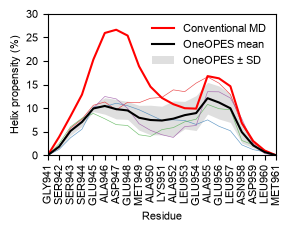

In [350]:
colors = plt.cm.Set1(range(4))

x = np.arange(len(residue_labels))

plt.figure(figsize=(7.5*cm2inch, 6*cm2inch))

# -------------------------------------------------------------------------
# Individual OPES replicas (thin gray lines)
# -------------------------------------------------------------------------
for j in range(4):
    plt.plot(
        x,
        100 * opes_probabilities[j],
        lw=0.45,
        color=colors[j],
        alpha=0.8
    )

# -------------------------------------------------------------------------
# Conventional MD
# -------------------------------------------------------------------------
plt.plot(
    x,
    100 * helix_probability_conv,
    color="red",
    lw=1.5,
    label="Conventional MD"
)

# -------------------------------------------------------------------------
# Mean ± SD of OPES
# -------------------------------------------------------------------------
plt.plot(
    x,
    100 * opes_mean,
    color="black",
    lw=1.5,
    label="OneOPES mean"
)

plt.fill_between(
    x,
    100 * (opes_mean - opes_sd),
    100 * (opes_mean + opes_sd),
    color="grey",
    lw = 0,
    alpha=0.25,
    label="OneOPES ± SD"
)

# -------------------------------------------------------------------------
# Formatting
# -------------------------------------------------------------------------
plt.xticks(x, residue_labels, rotation=90)

plt.xlim(0, len(residue_labels)-1)
plt.ylim(0, 30)

plt.ylabel("Helix propensity (%)")
plt.xlabel("Residue")

plt.legend(frameon=False)

plt.tight_layout()

plt.savefig(
    "images/Helix_propensity_comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

#### Biased computation. Block averaged conventional MD data.

In [340]:
BETA = 1/(KB*T)
n_blocks = 5

# =============================================================================
# Paths
# =============================================================================

path_folding = r"C:/Users/vacaa/Documents/REPORTS/170/data/Folding"

# =============================================================================
# Conventional MD
# =============================================================================

traj = md.load(
    f"{path_folding}/FCP1/plumed/chainB.xtc",
    top=f"{path_folding}/FCP1/plumed/chainB.pdb"
)

# =============================================================================
# Block averaging
# =============================================================================

dssp = md.compute_dssp(traj)
helix = np.isin(dssp, ["H", "G", "I"])

# Split trajectory into blocks
helix_blocks = np.array_split(helix, n_blocks, axis=0)

# Compute helix propensity for each block
block_propensities = np.array([
    block.mean(axis=0)
    for block in helix_blocks
])

# Mean and SD across blocks
helix_probability_conv = block_propensities.mean(axis=0)
helix_probability_conv_sd = block_propensities.std(axis=0, ddof=1)

# =============================================================================
# One-OPES trajectories
# =============================================================================

opes_probabilities = []

for j in range(1, 5):
    print(f"Processing One_OPES_{j}")

    traj = md.load(
        f"{path_folding}/One_OPES_{j}/0/md_0_2.xtc",
        top=f"{path_folding}/One_OPES_{j}/0/fcp1.pdb"
    )

    # Keep only protein atoms
    protein_idx = traj.topology.select("protein")
    traj_protein = traj.atom_slice(protein_idx)

    # Compute DSSP on the protein only
    dssp = md.compute_dssp(traj_protein)

    # Count all helix types (H = α, G = 3₁₀, I = π)
    helix = np.isin(dssp, ["H", "G", "I"])

    #Compute weights
    bias = colvar.loc[colvar['Repeat']==j, 'opes1.bias'].to_numpy()[::50]
    logweights = BETA * (bias - np.max(bias))
    weights = np.exp(logweights)
    weights /= np.sum(weights)

    # Per-residue helix occupancy
    helix_probability = np.average(
                                    helix.astype(float),
                                    axis=0,
                                    weights=weights
                                )
    opes_probabilities.append(helix_probability)

opes_probabilities = np.array(opes_probabilities)

opes_mean = opes_probabilities.mean(axis=0)
opes_sd = opes_probabilities.std(axis=0)

# =============================================================================
# DataFrame
# =============================================================================

df = pd.DataFrame({
    "Residue": residue_labels,
    "Helix_conv_%": 100 * helix_probability_conv,
    "Helix_conv_SD_%": 100 * helix_probability_conv_sd,
    "Helix_OPES_mean_%": 100 * opes_mean,
    "Helix_OPES_SD_%": 100 * opes_sd
})

for j in range(4):
    df[f"Helix_OPES_{j+1}_%"] = 100 * opes_probabilities[j]

# display(df)

Processing One_OPES_1
Processing One_OPES_2
Processing One_OPES_3
Processing One_OPES_4


#### Plotting. All conventional 5 blocks and biased data

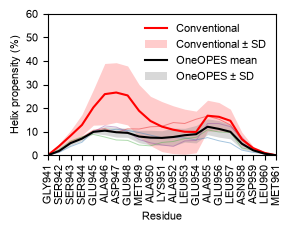

In [349]:
colors = plt.cm.Set1(range(4))

x = np.arange(len(residue_labels))

plt.figure(figsize=(7.5*cm2inch, 6*cm2inch))

# -------------------------------------------------------------------------
# Individual OPES replicas (thin gray lines)
# -------------------------------------------------------------------------
for j in range(4):
    plt.plot(
        x,
        100 * opes_probabilities[j],
        lw=0.7,
        alpha = 0.45,
        color=colors[j],
    )

# -------------------------------------------------------------------------
# Conventional MD
# -------------------------------------------------------------------------
plt.plot(
    x,
    df["Helix_conv_%"],
    color="red",
    lw=1.5,
    label="Conventional"
)

# Mean ± SD
plt.fill_between(
    x,
    df["Helix_conv_%"] - df["Helix_conv_SD_%"],
    df["Helix_conv_%"] + df["Helix_conv_SD_%"],
    color="red",
    alpha=0.20,
    lw = 0,
    label="Conventional ± SD"
)

# -------------------------------------------------------------------------
# Mean ± SD of OneOPES
# -------------------------------------------------------------------------
plt.plot(
    x,
    100 * opes_mean,
    color="black",
    lw=1.5,
    label="OneOPES mean"
)

plt.fill_between(
    x,
    100 * (opes_mean - opes_sd),
    100 * (opes_mean + opes_sd),
    color="grey",
    lw = 0,
    alpha=0.30,
    label="OneOPES ± SD"
)

# -------------------------------------------------------------------------
# Formatting
# -------------------------------------------------------------------------
plt.xticks(x, residue_labels, rotation=90)

plt.xlim(0, len(residue_labels)-1)
plt.ylim(0, 60)

plt.ylabel("Helix propensity (%)")
plt.xlabel("Residue")

plt.legend(frameon=False)

plt.tight_layout()

plt.savefig(
    "images/Helix_propensity_comparison_5blocks.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

### Conventional MD folding mechanism

In [160]:
colvar_convtraj = md.load(
    r"c:\Users\vacaa\Documents\REPORTS\170\data\Folding\FCP1\plumed\chainB.xtc",
    top=r"c:\Users\vacaa\Documents\REPORTS\170\data\Folding\FCP1\plumed\chainB.pdb"
)

# Keep only protein atoms
protein_idx = colvar_convtraj.topology.select("protein")
traj_protein = colvar_convtraj.atom_slice(protein_idx)

# Compute DSSP on the protein only
dssp = md.compute_dssp(traj_protein)
# Count all helix types (H = α, G = 3₁₀, I = π)
helix = np.isin(dssp, ["H", "G", "I"])

# ============================================================
# Sort trajectory by alpha
# ============================================================

alpha = colvar_conv[
    "alpha"
].to_numpy(dtype=float)

# Sort frame indices by alpha
sort_idx = np.argsort(alpha)

# Reorder all frame-dependent quantities
alpha_sorted = alpha[sort_idx]
helix_sorted = helix[sort_idx]


# ============================================================
# Calculate helix probability in alpha bins
# ============================================================

alpha_min = 0
alpha_max = 15

alpha_bins = np.arange(
    alpha_min,
    alpha_max + 1,
    1
)

helix_probabilities = []

for i in range(15):

    # Frames with:
    # i <= alpha < i+1
    mask = (
        (alpha_sorted >= i) &
        (alpha_sorted < i + 1)
    )

    print(
        f"alpha = {i}-{i+1}: "
        f"{mask.sum()} frames"
    )

    # Select frames
    helix_group = helix_sorted[mask]

    # Check that the bin contains frames
    if mask.sum() == 0:

        # No data in this alpha interval
        helix_probability = np.full(
            helix.shape[1],
            np.nan
        )

    else:

        # Weighted helix probability per residue
        helix_probability = np.average(
            helix_group.astype(float),
            axis=0,
        )

    helix_probabilities.append(
        helix_probability
    )


# Convert to 2D array
helix_probabilities = np.array(
    helix_probabilities
)

print(
    "Shape:",
    helix_probabilities.shape
)


alpha = 0-1: 135490 frames
alpha = 1-2: 17833 frames
alpha = 2-3: 11451 frames
alpha = 3-4: 6666 frames
alpha = 4-5: 4300 frames
alpha = 5-6: 5054 frames
alpha = 6-7: 3995 frames
alpha = 7-8: 2395 frames
alpha = 8-9: 2167 frames
alpha = 9-10: 2842 frames
alpha = 10-11: 1804 frames
alpha = 11-12: 2979 frames
alpha = 12-13: 2252 frames
alpha = 13-14: 770 frames
alpha = 14-15: 3 frames
Shape: (15, 21)


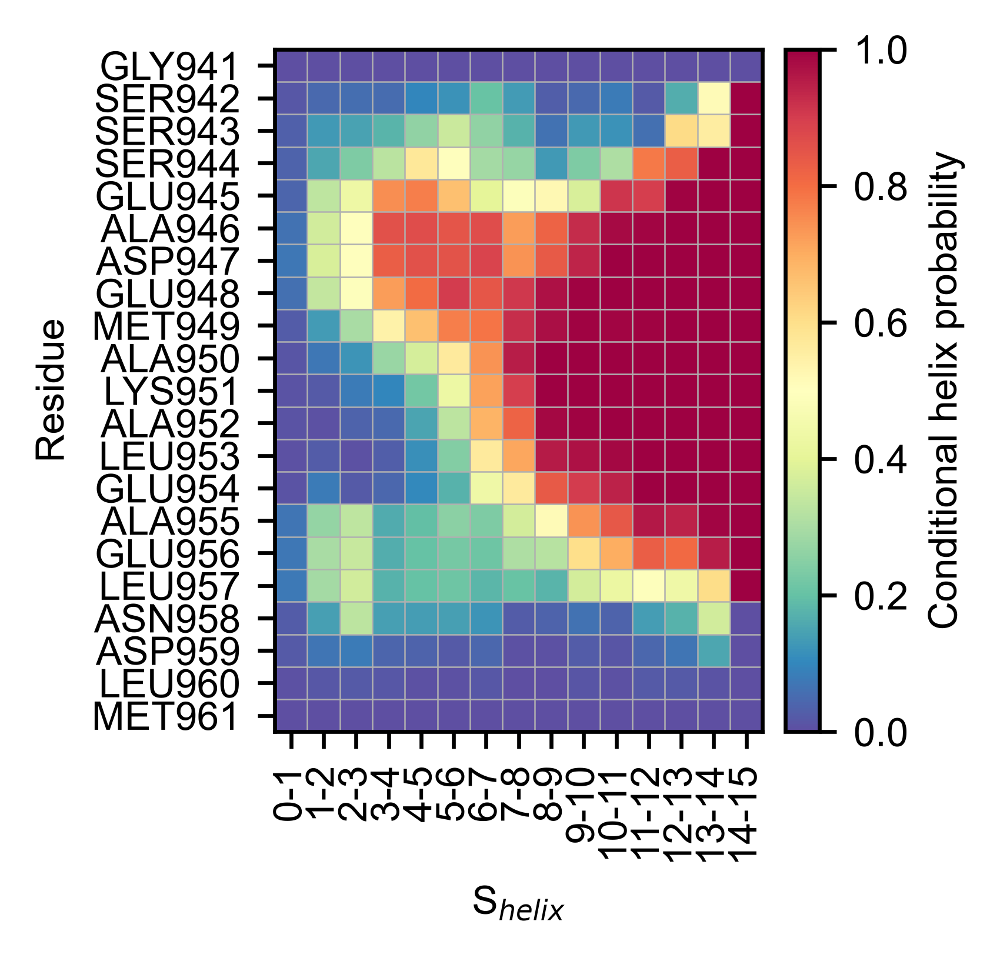

In [161]:
fig, ax = plt.subplots(
    figsize=(9 * cm2inch, 7 * cm2inch),
    dpi=600
)

im = ax.imshow(
    helix_probabilities.T,
    cmap="Spectral_r",
    vmin=0,
    vmax=1,
    aspect="equal",
    interpolation="nearest"
)

# ------------------------------------------------------------
# Grid lines between cells
# ------------------------------------------------------------

ax.set_xticks(np.arange(-0.5, 15, 1), minor=True)
ax.set_yticks(
    np.arange(-0.5, len(residue_labels), 1),
    minor=True
)

ax.grid(
    which="minor",
    linewidth=0.3
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# ------------------------------------------------------------
# Tick labels
# ------------------------------------------------------------

ax.set_xticks(np.arange(15))
ax.set_xticklabels(
    [f"{i}-{i+1}" for i in range(15)],
    rotation=90
)

ax.set_yticks(np.arange(len(residue_labels)))
ax.set_yticklabels(residue_labels)

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel("S$_{helix}$")
ax.set_ylabel("Residue")

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    pad=0.02
)

cbar.set_label("Conditional helix probability")
cbar.set_ticks(np.arange(0,1.01,0.2))

cbar.outline.set_edgecolor("black")
cbar.outline.set_linewidth(0.8)

# ------------------------------------------------------------

plt.tight_layout()

plt.savefig(
    "images/Binned_helix_probability_along_alpha_conventional_MD.png",
    dpi=600,
)

plt.show()

### OPES MD folding mechanism

In [156]:
repeat = 4

traj = md.load(
        f"{path_folding}/One_OPES_{repeat}/0/md_0_2.xtc",
        top=f"{path_folding}/One_OPES_{repeat}/0/fcp1.pdb"
    )

# Keep only protein atoms
protein_idx = traj.topology.select("protein")
traj_protein = traj.atom_slice(protein_idx)

# Compute DSSP on the protein only
dssp = md.compute_dssp(traj_protein)

# Count all helix types (H = α, G = 3₁₀, I = π)
helix = np.isin(dssp, ["H", "G", "I"])


# ============================================================
# Sort trajectory by alpha
# ============================================================
alpha = colvar_rerun.loc[
    colvar_rerun["Repeat"] == repeat,
    "alpha"
].to_numpy(dtype=float)

# Sort frame indices by alpha
sort_idx = np.argsort(alpha)

# Reorder all frame-dependent quantities
alpha_sorted = alpha[sort_idx]
helix_sorted = helix[sort_idx]

# ============================================================
# Weights
# ============================================================

bias = colvar.loc[
    colvar["Repeat"] == repeat,
    "opes1.bias"
].to_numpy(dtype=float)[::50]

logweights = BETA * (bias - np.max(bias))
weights = np.exp(logweights)
weights /= np.sum(weights)

weights_sorted = weights[sort_idx]


# ============================================================
# Calculate helix probability in alpha bins
# ============================================================

alpha_min = 0
alpha_max = 15

alpha_bins = np.arange(
    alpha_min,
    alpha_max + 1,
    1
)

helix_probabilities = []

for i in range(15):

    # Frames with:
    # i <= alpha < i+1
    mask = (
        (alpha_sorted >= i) &
        (alpha_sorted < i + 1)
    )

    print(
        f"alpha = {i}-{i+1}: "
        f"{mask.sum()} frames"
    )

    # Select frames
    helix_group = helix_sorted[mask]
    weights_group = weights_sorted[mask]

    # Check that the bin contains frames
    if mask.sum() == 0:

        # No data in this alpha interval
        helix_probability = np.full(
            helix.shape[1],
            np.nan
        )

    else:

        # Normalize weights within this alpha bin to have a conditional probability
        weights_group = weights_group / weights_group.sum()
        
        # Weighted helix probability per residue
        helix_probability = np.average(
            helix_group.astype(float),
            axis=0,
            weights=None
        )

    helix_probabilities.append(
        helix_probability
    )


# Convert to 2D array
helix_probabilities = np.array(
    helix_probabilities
)

print(
    "Shape:",
    helix_probabilities.shape
)

alpha = 0-1: 1023 frames
alpha = 1-2: 657 frames
alpha = 2-3: 521 frames
alpha = 3-4: 447 frames
alpha = 4-5: 460 frames
alpha = 5-6: 271 frames
alpha = 6-7: 241 frames
alpha = 7-8: 247 frames
alpha = 8-9: 249 frames
alpha = 9-10: 205 frames
alpha = 10-11: 183 frames
alpha = 11-12: 167 frames
alpha = 12-13: 150 frames
alpha = 13-14: 139 frames
alpha = 14-15: 41 frames
Shape: (15, 21)


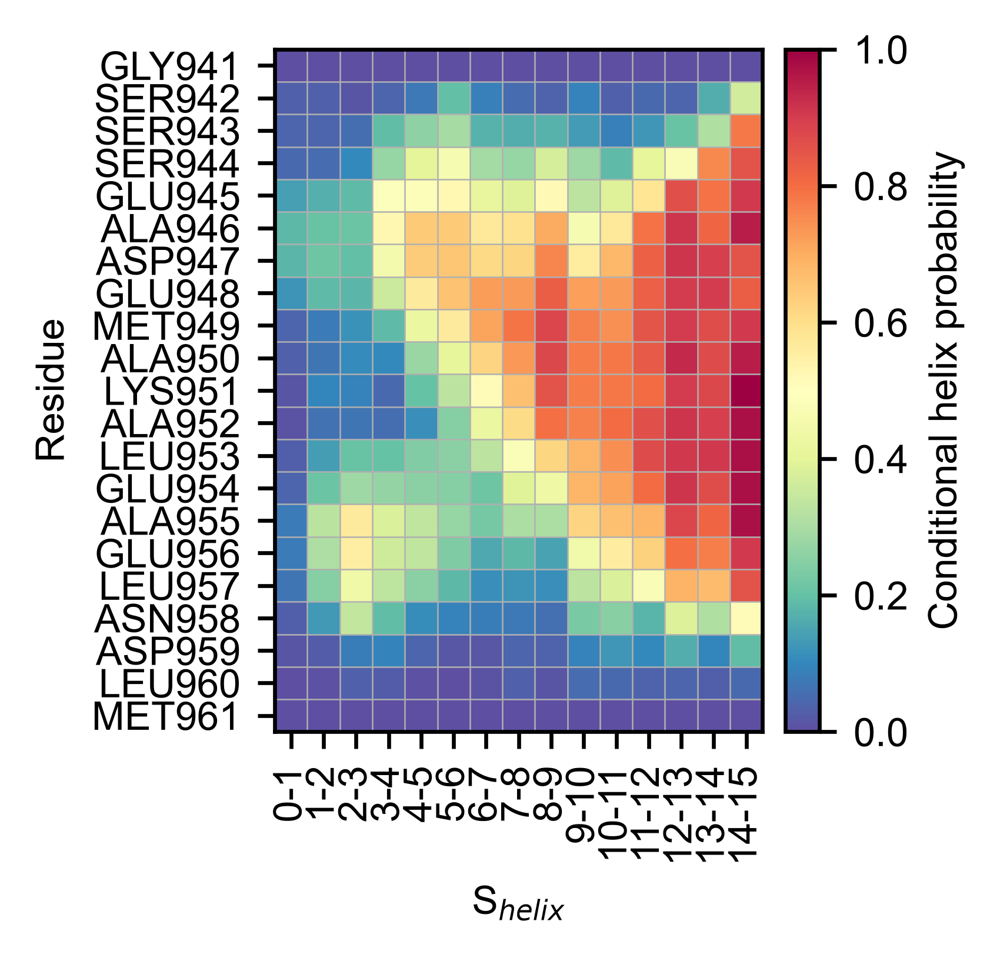

In [157]:
fig, ax = plt.subplots(
    figsize=(9 * cm2inch, 7 * cm2inch),
    dpi=600
)

im = ax.imshow(
    helix_probabilities.T,
    cmap="Spectral_r",
    vmin=0,
    vmax=1,
    aspect="equal",
    interpolation="nearest"
)

# ------------------------------------------------------------
# Grid lines between cells
# ------------------------------------------------------------

ax.set_xticks(np.arange(-0.5, 15, 1), minor=True)
ax.set_yticks(
    np.arange(-0.5, len(residue_labels), 1),
    minor=True
)

ax.grid(
    which="minor",
    linewidth=0.3
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# ------------------------------------------------------------
# Tick labels
# ------------------------------------------------------------

ax.set_xticks(np.arange(15))
ax.set_xticklabels(
    [f"{i}-{i+1}" for i in range(15)],
    rotation=90
)

ax.set_yticks(np.arange(len(residue_labels)))
ax.set_yticklabels(residue_labels)

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel("S$_{helix}$")
ax.set_ylabel("Residue")

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    pad=0.02
)

cbar.set_label("Conditional helix probability")
cbar.set_ticks(np.arange(0,1.01,0.2))

cbar.outline.set_edgecolor("black")
cbar.outline.set_linewidth(0.8)

# ------------------------------------------------------------

plt.tight_layout()

plt.savefig(
    f"images/Binned_helix_probability_along_alpha_OPES_repeat_{repeat}.png",
    dpi=600,
)

plt.show()

## Binding

### Read OneOPES data

In [108]:
# OneOPES MD
colvar_list = []
path_folding = r'C:/Users/vacaa/Documents/REPORTS/170/data/Binding'

for i,j in enumerate([10,11,12,13]):
    for k in range(8):
        colvar = load_dataframe(f'{path_folding}/{j}/{k}/COLVAR.{k}')
        colvar_list.append(colvar)
        colvar['Replica'] = [k]*len(colvar)
        colvar['Repeat'] = [i+1]*len(colvar)
    

colvar = pd.concat(colvar_list)
colvar['radius'] = np.sqrt(colvar['poa_d.proj']**2 + colvar['poa_d.ext']**2)
colvar.replace(np.nan, 0, inplace=True)
colvar['bias_sum'] = np.sum(colvar[['opes1.bias','opes2.bias','opesX.bias']].to_numpy(), axis = 1)
colvar['bias_sum_all'] = np.sum(colvar.filter(like='.bias').to_numpy(), axis = 1)
colvar['time']/=1000

#Conventional MD
path_folding = r'C:/Users/vacaa/Documents/REPORTS/170/data/Binding/20_nobias/1'

colvar_conv = load_dataframe(f'{path_folding}/COLVAR_RERUN')
colvar_conv['time']/= 10 #ns
colvar_conv["Time (us)"] = colvar_conv['time'] / 1000

colvar_conv.columns
colvar_conv.head()


path_folding = r'C:/Users/vacaa/Documents/REPORTS/170/data/Binding'


### Distance and bias over the time

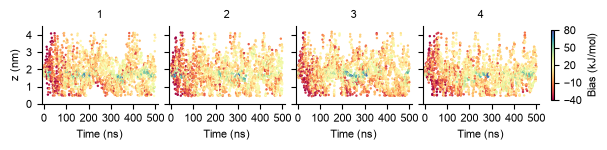

In [17]:
df = colvar[::100]
df = df[df["Replica"] == 1]

data_Y = "cmap_F_sum"
data_Y = "poa_d.proj"

def scatter(data, **kwargs):
    plt.scatter(
        data["time"],
        data[data_Y],
        c=data["opes1.bias"],
        cmap="Spectral",
        norm=mpl.colors.Normalize(*(-50, 80)),   # same style as hue_norm=(-10,20)
        s=3,
        linewidths=0,
    )

g = sns.FacetGrid(
    df,
    col="Repeat",
    margin_titles=False,
    height=1,
    aspect=2,
)

g.map_dataframe(scatter)

# Shared colorbar
sm = mpl.cm.ScalarMappable(
    cmap="Spectral",
    norm=mpl.colors.Normalize(*(-40, 80))
)
sm.set_array([])

cbar = g.fig.colorbar(
    sm,
    ax=g.axes,
    label="Bias (kJ/mol)",
    pad=0.02,
    shrink=0.9,
)
cbar.set_ticks(np.linspace(-40,80,5))

g.set(
    xlim=(-10, 510),
    ylim=(0, 4.5),
)
# More ticks
for ax in g.axes.flat:
    ax.set_xticks(np.arange(0, 501, 100))
    ax.set_yticks(np.arange(0, 1.1, 0.2))
    ax.set_yticks(np.arange(0, 4.5, 1.0))

g.set_titles(template="{col_name}", size=8)
g.fig.set_size_inches(16*cm2inch, 5*cm2inch)

g.set_axis_labels("Time (ns)", "z (nm)")
# g.set_axis_labels("Time (ns)", "S$_{F}$")

plt.savefig(f'images/{data_Y}_time_hue_bias.png', dpi = 600, bbox_inches="tight")

plt.show()

In [ ]:
df = colvar[::100]
df = df[df["Replica"] == 1]

# data_Y = "cmap_F_sum"
data_X = 'poa_d.proj'
data_Y = "cmap_N_sum"

def scatter(data, **kwargs):
    plt.scatter(
        data[data_X],
        data[data_Y],
        c=data["opes1.bias"],
        cmap="Spectral",
        norm=mpl.colors.Normalize(*(-50, 80)),   # same style as hue_norm=(-10,20)
        s=3,
        linewidths=0,
    )

g = sns.FacetGrid(
    df,
    col="Repeat",
    margin_titles=False,
    height=1,
    aspect=2,
)

g.map_dataframe(scatter)

# Shared colorbar
sm = mpl.cm.ScalarMappable(
    cmap="Spectral",
    norm=mpl.colors.Normalize(*(-40, 80))
)
sm.set_array([])

cbar = g.fig.colorbar(
    sm,
    ax=g.axes,
    label="Bias (kJ/mol)",
    pad=0.02,
    shrink=0.9,
)
cbar.set_ticks(np.linspace(-40,80,5))

g.set(
    xlim=(0.0, 4.5),
    ylim=(0, 1.),
)
# More ticks
for ax in g.axes.flat:
    ax.set_xticks(np.arange(0, 4.5, 1.0))
    ax.set_yticks(np.arange(0, 1.1, 0.2))

g.set_titles(template="{col_name}", size=8)
g.fig.set_size_inches(16*cm2inch, 5*cm2inch)

# g.set_axis_labels("Time (ns)", "z (nm)")
g.set_axis_labels("z (nm)", "S$_{N}$")

plt.savefig(f'images/{data_Y}_{data_X}_hue_bias_v2.png', dpi = 600, bbox_inches="tight")

plt.show()

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3059300710.py, line 52)

### Distance FES

<>:95: SyntaxWarning: invalid escape sequence '\D'
<>:95: SyntaxWarning: invalid escape sequence '\D'
C:\Users\vacaa\AppData\Local\Temp\ipykernel_24624\3001522491.py:95: SyntaxWarning: invalid escape sequence '\D'
  ax.set_ylabel("$\Delta F$ (kJ/mol)")


1
2
3
4


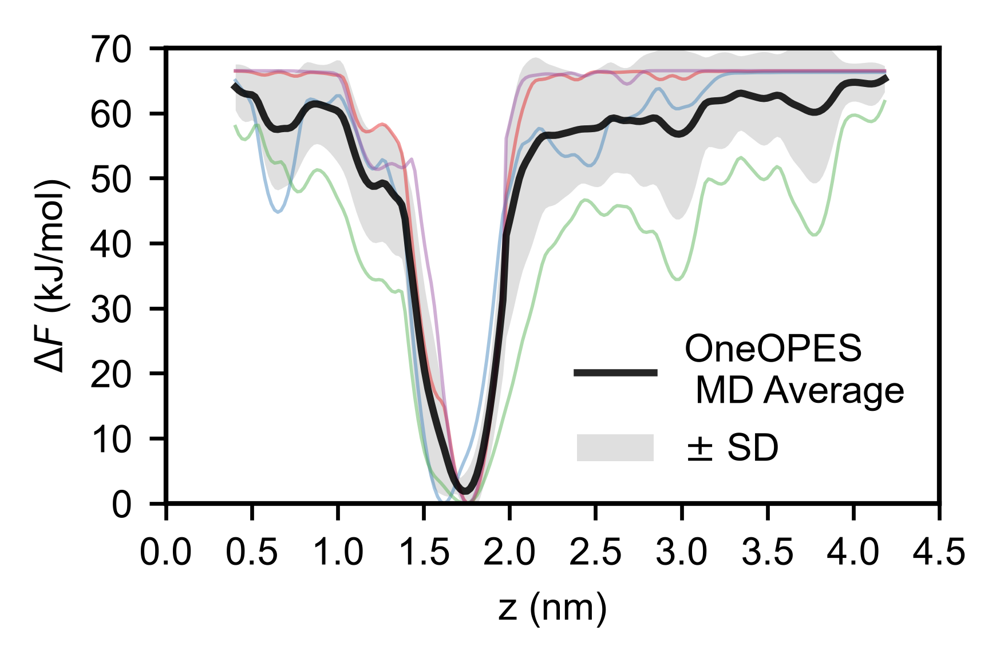

In [103]:
df = colvar[::1]
# df = df[df["Replica"] == 0]

T = 300
BETA = 1/(KB*T)

fes_list = []
grid_list = []

# Calculate FES for each repeat
for i in df["Repeat"].unique():
    print(i)
    data = df[df["Repeat"] == i]

    bias = data["bias_sum_all"].to_numpy()
    cv = data["poa_d.proj"].to_numpy()

    # numerically stable weights
    logweights = BETA * (bias - np.max(bias))
    w = np.exp(logweights)

    fes, grid, bounds, error = compute_fes(
        cv,
        weights=w,
        blocks=1,
        kbt=KB*T,
        bandwidth=0.01,
        scale_by="range",
        plot=False,
        plot_max_fes=100,
        eps=1e-10,
    )

    # normalize minimum to zero
    fes = fes - np.min(fes)

    fes_list.append(fes)
    grid_list.append(grid)


# Convert to arrays
fes_array = np.array(fes_list)
grid = grid_list[0]

# Mean and standard deviation
fes_mean = np.mean(fes_array, axis=0)
fes_std = np.std(fes_array, axis=0)


# ----------------------------
# Publication quality plotting
# ----------------------------

fig, ax = plt.subplots(
    figsize=(7.5*cm2inch, 5*cm2inch),
    dpi=600
)

colors = plt.cm.Set1(range(len(df["Repeat"].unique())))

# Individual repeats
for i, fes in enumerate(fes_array):
    ax.plot(
        grid,
        fes,
        color=colors[i],
        lw=0.7,
        alpha=0.45,
        # label=f"Repeat {i+1}"
    )

# Average FES
ax.plot(
    grid,
    fes_mean,
    color="black",
    lw=1.5,
    alpha=0.85,
    label="OneOPES\n MD Average"
)

# Standard deviation envelope
ax.fill_between(
    grid,
    fes_mean - fes_std,
    fes_mean + fes_std,
    color="gray",
    alpha=0.25,
    linewidth=0,
    label=r"$\pm$ SD"
)

# Labels and style
ax.set_xlabel("z (nm)")
ax.set_ylabel("$\Delta F$ (kJ/mol)")

ax.set_xlim(0, 4.5)
ax.set_ylim(0, 70)
ax.set_xticks(np.arange(0, 4.51, 0.5))
ax.set_yticks(np.arange(0, 71, 10))


ax.legend(
    frameon=False,
)

for spine in ax.spines.values():
    spine.set_linewidth(1)

plt.tight_layout()
plt.savefig('images/Distance_FES_v3_all.png', dpi = 600)
plt.show()

### Convergence plot

In [ ]:
df = colvar[::1]
# df = df[df["Replica"] == 0]

T = 300
BETA = 1/(KB*T)

fes_list = []
grid_list = []

# Calculate FES for each repeat
for i in df["Repeat"].unique():
    print(i)
    data = df[df["Repeat"] == i]

    bias = data["bias_sum"].to_numpy()
    cv = data["poa_d.proj"].to_numpy()

    # numerically stable weights
    logweights = BETA * (bias - np.max(bias))
    w = np.exp(logweights)

    fes, grid, bounds, error = compute_fes(
        cv,
        weights=w,
        blocks=1,
        kbt=KB*T,
        bandwidth=0.01,
        scale_by="range",
        plot=False,
        plot_max_fes=100,
        eps=1e-10,
    )

    # normalize minimum to zero
    fes = fes - np.min(fes)

    fes_list.append(fes)
    grid_list.append(grid)


# Convert to arrays
fes_array = np.array(fes_list)
grid = grid_list[0]

# Mean and standard deviation
fes_mean = np.mean(fes_array, axis=0)
fes_std = np.std(fes_array, axis=0)


# ----------------------------
# Publication quality plotting
# ----------------------------

fig, ax = plt.subplots(
    figsize=(7.5*cm2inch, 5*cm2inch),
    dpi=600
)

colors = plt.cm.Set1(range(len(df["Repeat"].unique())))

# Individual repeats
for i, fes in enumerate(fes_array):
    ax.plot(
        grid,
        fes,
        color=colors[i],
        lw=0.7,
        alpha=0.45,
        # label=f"Repeat {i+1}"
    )

# Average FES
ax.plot(
    grid,
    fes_mean,
    color="black",
    lw=1.5,
    alpha=0.85,
    label="OneOPES\n MD Average"
)

# Standard deviation envelope
ax.fill_between(
    grid,
    fes_mean - fes_std,
    fes_mean + fes_std,
    color="gray",
    alpha=0.25,
    linewidth=0,
    label=r"$\pm$ SD"
)

# Labels and style
ax.set_xlabel("z (nm)")
ax.set_ylabel("$\Delta F$ (kJ/mol)")

ax.set_xlim(0, 4.5)
ax.set_ylim(0, 70)
ax.set_xticks(np.arange(0, 4.51, 0.5))
ax.set_yticks(np.arange(0, 71, 10))


ax.legend(
    frameon=False,
)

for spine in ax.spines.values():
    spine.set_linewidth(1)

plt.tight_layout()
plt.savefig('images/Distance_FES_v2_all.png', dpi = 600)
plt.show()

Determined value: 57.353526965051806 ± 4.158980784523169


c:\Users\vacaa\Documents\REPORTS\170\Code\.venv\Lib\site-packages\numpy\_core\_methods.py:188: RuntimeWarning: invalid value encountered in subtract
  x = um.subtract(arr, arrmean, out=...)


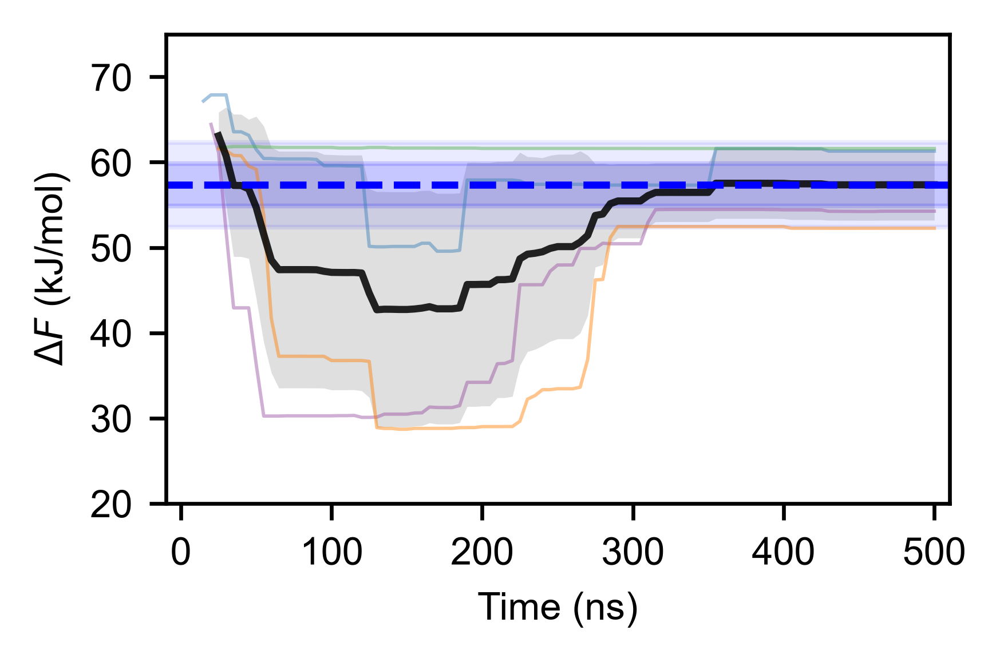

In [104]:

fragments = 100
time_min = 0

df = colvar[colvar["Replica"] == 0]

T = 300
BETA = 1/(KB*T)

time_max = df["time"].max()

# Store convergence curves
deltaF_all = []

for rep in df["Repeat"].unique():

    data_rep = df[df["Repeat"] == rep]

    deltaF_metad = np.empty(fragments)
    time_analyse = np.empty(fragments)

    for i in range(fragments):

        time_analyse[i] = (
            (time_max - time_min) / fragments * (i + 1)
            + time_min
        )

        data = data_rep[
            data_rep["time"].between(time_min, time_analyse[i])
        ]

        bias = data["bias_sum_all"].to_numpy()
        cv = data["poa_d.proj"].to_numpy()

        # stable weights
        logweights = BETA * (bias - np.max(bias))
        w = np.exp(logweights)

        fes, grid, bounds, error = compute_fes(
            cv,
            weights=w,
            blocks=1,
            kbt=KB*T,
            bandwidth=0.01,
            scale_by="range",
            plot=False,
            plot_max_fes=50,
            eps=1e-10,
        )

        # Define basin
        mask = np.full(fes.shape, True)
        mask[grid > 3.5] = False

        deltaF_metad[i] = calcDeltaF(
            fes,
            basinMask=mask,
            kbt=KBT
        )

    deltaF_all.append(deltaF_metad)


# Convert to array
deltaF_all = np.array(deltaF_all)

# Average and standard deviation
deltaF_mean = np.mean(deltaF_all, axis=0)
deltaF_std = np.std(deltaF_all, axis=0)


# --------------------------
# Plot
# --------------------------

fig, ax = plt.subplots(
    figsize=(7.5*cm2inch,5*cm2inch),
    dpi=600
)

colors = plt.cm.Set1(df["Repeat"].unique())

# Individual repeats
for i, deltaF in enumerate(deltaF_all):
    ax.plot(
        time_analyse,
        deltaF,
        color=colors[i],
        lw=0.7,
        alpha=0.45,
        # label=f"Repeat {i+1}"
    )
    
# Average
ax.plot(
    time_analyse,
    deltaF_mean,
    color="black",
    lw=1.5,
    alpha=0.85,
    label="Average"
)

# Standard deviation
ax.fill_between(
    time_analyse,
    deltaF_mean - deltaF_std,
    deltaF_mean + deltaF_std,
    color="gray",
    alpha=0.25,
    linewidth=0,
    label="± SD"
)

# Last values
deltaF_final = deltaF_mean[-1]
ax.axhline(
    deltaF_final,
    color="blue",
    lw=1.5,
    linestyle="--",
    label=r"OneOPES MD $\Delta F_{\mathrm{final}}$"
)

ax.axhspan(
    deltaF_final - KBT,
    deltaF_final + KBT,
    color="blue",
    alpha=0.15,
    label=r"$\Delta F_{\mathrm{final}}\pm k_BT$"
)

ax.axhspan(
    deltaF_final - 2*KBT,
    deltaF_final + 2*KBT,
    color="blue",
    alpha=0.08,
    label=r"$\Delta F_{\mathrm{final}}\pm 2k_BT$"
)

# Cosmetics
ax.set_xlabel("Time (ns)")
ax.set_ylabel(r"$\Delta F$ (kJ/mol)")


# ax.legend(
#     frameon=False,
#     loc = 'lower right'
# )
plt.xlim(-10,510)
plt.ylim(20,75)




plt.tight_layout()
print(f'Determined value: {deltaF_final} ± {deltaF_std[-1]}')
plt.savefig('images/Convergence_distance_v2_0.png', dpi = 600)
plt.show()

In [6]:
f = 0.3
Fcorr = KBT * np.log(np.pi * (f*10)**2/1666)
print('corrcetion: ', Fcorr)

corrcetion:  -10.167488873227803


### FES cmap_N

<>:96: SyntaxWarning: invalid escape sequence '\D'
<>:96: SyntaxWarning: invalid escape sequence '\D'
C:\Users\vacaa\AppData\Local\Temp\ipykernel_24624\3033756044.py:96: SyntaxWarning: invalid escape sequence '\D'
  ax.set_ylabel("$\Delta F$ (kJ/mol)")


1
2
3
4


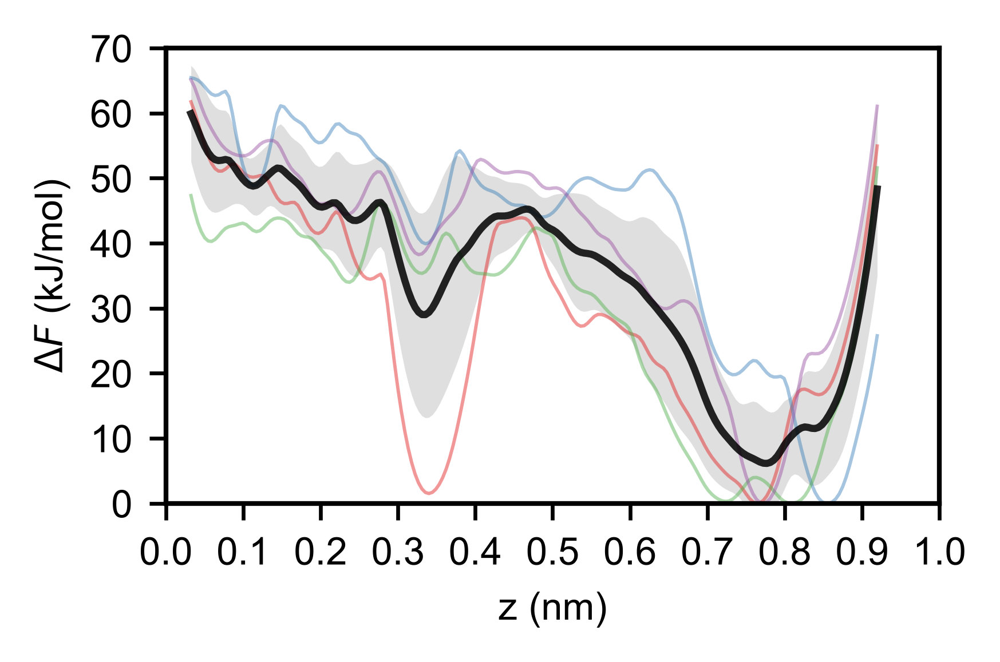

In [109]:
df = colvar[::1]
# df = df[df["Replica"] == 0]

T = 300
BETA = 1/(KB*T)

fes_list = []
grid_list = []

# Calculate FES for each repeat
for i in df["Repeat"].unique():
    print(i)
    data = df[df["Repeat"] == i]

    bias = data["bias_sum"].to_numpy()
    bias = data.loc[data["cmap_F_sum"] < 0.4, "bias_sum"].to_numpy()
    cv = data.loc[data["cmap_F_sum"] < 0.4, "cmap_N_sum"].to_numpy()

    # numerically stable weights
    logweights = BETA * (bias - np.max(bias))
    w = np.exp(logweights)

    fes, grid, bounds, error = compute_fes(
        cv,
        weights=w,
        blocks=1,
        kbt=KB*T,
        bandwidth=0.01,
        scale_by="range",
        plot=False,
        plot_max_fes=100,
        eps=1e-10,
    )

    # normalize minimum to zero
    fes = fes - np.min(fes)

    fes_list.append(fes)
    grid_list.append(grid)


# Convert to arrays
fes_array = np.array(fes_list)
grid = grid_list[0]

# Mean and standard deviation
fes_mean = np.mean(fes_array, axis=0)
fes_std = np.std(fes_array, axis=0)


# ----------------------------
# Publication quality plotting
# ----------------------------

fig, ax = plt.subplots(
    figsize=(7.5*cm2inch, 5*cm2inch),
    dpi=600
)

colors = plt.cm.Set1(range(len(df["Repeat"].unique())))

# Individual repeats
for i, fes in enumerate(fes_array):
    ax.plot(
        grid,
        fes,
        color=colors[i],
        lw=0.7,
        alpha=0.45,
        # label=f"Repeat {i+1}"
    )

# Average FES
ax.plot(
    grid,
    fes_mean,
    color="black",
    lw=1.5,
    alpha=0.85,
    label="OneOPES\n MD Average"
)

# Standard deviation envelope
ax.fill_between(
    grid,
    fes_mean - fes_std,
    fes_mean + fes_std,
    color="gray",
    alpha=0.25,
    linewidth=0,
    label=r"$\pm$ SD"
)

# Labels and style
ax.set_xlabel("z (nm)")
ax.set_ylabel("$\Delta F$ (kJ/mol)")

ax.set_xlim(0, 1.0)
ax.set_ylim(0, 70)
ax.set_xticks(np.arange(0, 1.01, 0.1))
ax.set_yticks(np.arange(0, 71, 10))


# ax.legend(
#     frameon=False,
# )

for spine in ax.spines.values():
    spine.set_linewidth(1)

plt.tight_layout()
plt.savefig('images/cmap_N_FES_v2_all_no_legend.png', dpi = 600)
plt.show()

### 2D distance R/Z FES

<>:129: SyntaxWarning: invalid escape sequence '\D'
<>:129: SyntaxWarning: invalid escape sequence '\D'
C:\Users\vacaa\AppData\Local\Temp\ipykernel_31840\1484238768.py:129: SyntaxWarning: invalid escape sequence '\D'
  "$\Delta F$ (kJ/mol)",


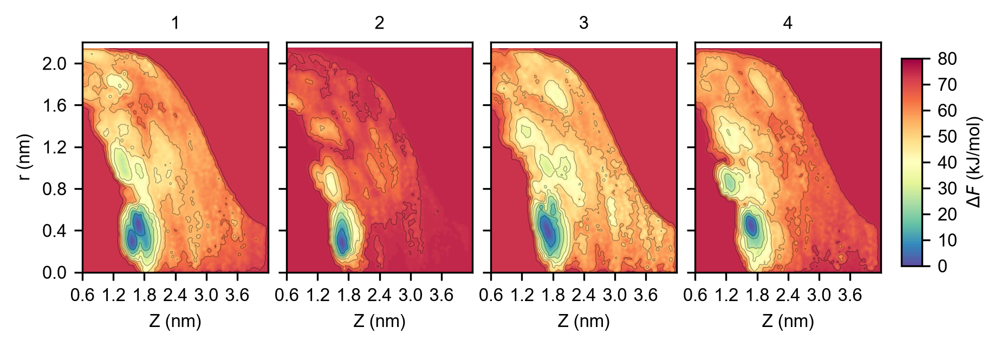

In [115]:
# -----------------------------
# Data preparation
# -----------------------------

df = colvar.copy()
# df = df[df["Replica"] == 0]
df = df[df["time"] > 0]

var1 = "poa_d.proj"
var2 = "poa_d.ext"

T = 300
BETA = 1/(KB*T)


# -----------------------------
# Figure setup
# -----------------------------

fig, axes = plt.subplots(
    1, 4,
    figsize=(16*cm2inch, 5*cm2inch),
    dpi=300,
    sharex=True,
    sharey=True
)

fig.subplots_adjust(
    left=0.08,
    right=0.86,
    bottom=0.18,
    top=0.90,
    wspace=0.1
)


pp = None


# -----------------------------
# Calculate and plot FES
# -----------------------------

for i, ax in enumerate(axes):

    data = df[df["Repeat"] == i+1]

    bias = data["opes1.bias"].to_numpy()

    cv1 = data[var1].to_numpy()
    cv2 = data[var2].to_numpy()

    cv = np.vstack([cv1, cv2])


    # weights
    logweights = BETA * (bias - np.max(bias))
    w = np.exp(logweights)
    w /= np.sum(w)


    fes, grid, bounds, error = compute_fes(
        cv.T,
        weights=w,
        blocks=1,
        kbt=KB*T,
        bandwidth=0.005,
        scale_by="range",
        plot=False,
        plot_max_fes=100,
        eps=1e-10,
        backend="KDEpy",
    )


    extent = [item for sublist in bounds for item in sublist]


    pp = ax.contourf(
        fes,
        extent=extent,
        levels=np.linspace(0, 80,101),
        cmap="Spectral_r"
    )


    # contour lines
    ax.contour(
        fes,
        extent=extent,
        levels=np.linspace(0, 81, 10),
        colors="black",
        linewidths=0.3,
        alpha=0.4
    )

    ax.set_title(f"{i+1}",)

    ax.set_xlabel(r"Z (nm)", )

    if i == 0:
        ax.set_ylabel(r"r (nm)", )

    if i > 0:
        ax.tick_params(
            direction="out",
            top=False,
            left=True,
            right=False,
            # length=4,
            # width=1
        )


# -----------------------------
# Shared colorbar
# -----------------------------

cbar_ax = fig.add_axes([0.88, 0.20, 0.02, 0.65])

cbar = fig.colorbar(
    pp,
    cax=cbar_ax
)
cbar.set_ticks(np.linspace(0,80,9))


cbar.set_label(
    "$\Delta F$ (kJ/mol)",
)


# -----------------------------
# Axis limits
# -----------------------------

for ax in axes:
    ax.set_xlim(0.6, 4.2)
    ax.set_ylim(0, 2.2)
    ax.set_xticks(np.arange(0.6, 4.2, .6))
    ax.set_yticks(np.arange(0, 2.1, 0.4))

# -----------------------------
# Save figure
# -----------------------------

plt.savefig(
    "images/2D_FES_disntaceRZ_all.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

### 2D FES Orientation cmap_N_sum

<>:130: SyntaxWarning: invalid escape sequence '\D'
<>:130: SyntaxWarning: invalid escape sequence '\D'
C:\Users\vacaa\AppData\Local\Temp\ipykernel_27800\2547864068.py:130: SyntaxWarning: invalid escape sequence '\D'
  "$\Delta F$ (kJ/mol)",


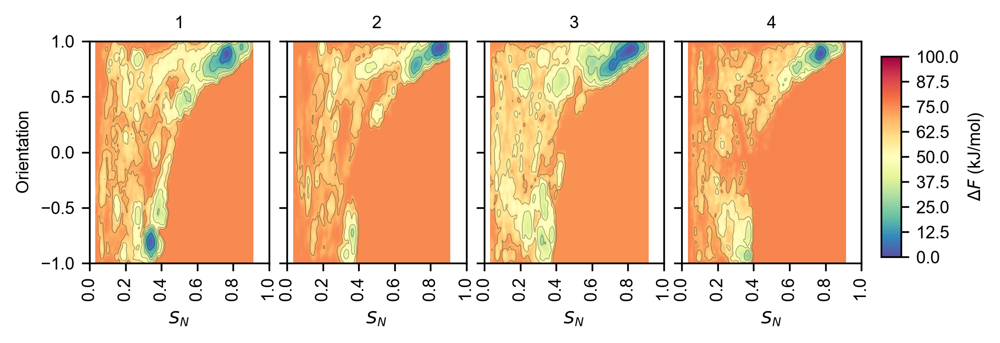

In [173]:
# -----------------------------
# Data preparation
# -----------------------------

df = colvar.copy()
df = df[df["Replica"] == 0]
df = df[df["time"] > 0]

var1 = "cmap_N_sum"
var2 = "orientation"

T = 300
BETA = 1/(KB*T)


# -----------------------------
# Figure setup
# -----------------------------

fig, axes = plt.subplots(
    1, 4,
    figsize=(16*cm2inch, 5*cm2inch),
    dpi=300,
    sharex=True,
    sharey=True
)

fig.subplots_adjust(
    left=0.08,
    right=0.86,
    bottom=0.18,
    top=0.90,
    wspace=0.1
)


pp = None


# -----------------------------
# Calculate and plot FES
# -----------------------------

for i, ax in enumerate(axes):

    data = df[df["Repeat"] == i+1]

    bias = data["bias_sum"].to_numpy()

    cv1 = data[var1].to_numpy()
    cv2 = data[var2].to_numpy()

    cv = np.vstack([cv1, cv2])


    # weights
    logweights = BETA * (bias - np.max(bias))
    w = np.exp(logweights)
    w /= np.sum(w)


    fes, grid, bounds, error = compute_fes(
        cv.T,
        weights=w,
        blocks=1,
        kbt=KB*T,
        bandwidth=0.005,
        scale_by="range",
        plot=False,
        plot_max_fes=100,
        eps=1e-10,
        backend="KDEpy",
    )


    extent = [item for sublist in bounds for item in sublist]


    pp = ax.contourf(
        fes,
        extent=extent,
        levels=np.linspace(0, 100,101),
        cmap="Spectral_r"
    )


    # contour lines
    ax.contour(
        fes,
        extent=extent,
        levels=np.linspace(0, 101, 10),
        colors="black",
        linewidths=0.3,
        alpha=0.4
    )

    ax.set_title(f"{i+1}",)

    ax.set_xlabel(r"Z (nm)", )
    ax.set_xlabel(r"$S_{N}$", )

    if i == 0:
        ax.set_ylabel(r"Orientation", )

    if i > 0:
        ax.tick_params(
            direction="out",
            top=False,
            left=True,
            right=False,
            # length=4,
            # width=1
        )


# -----------------------------
# Shared colorbar
# -----------------------------

cbar_ax = fig.add_axes([0.88, 0.20, 0.02, 0.65])

cbar = fig.colorbar(
    pp,
    cax=cbar_ax
)
cbar.set_ticks(np.linspace(0,100,9))


cbar.set_label(
    "$\Delta F$ (kJ/mol)",
)


# -----------------------------
# Axis limits
# -----------------------------

for ax in axes:
    ax.set_xlim(0, 1.0)
    ax.set_ylim(-1, 1.0)
    ax.set_xticks(np.arange(0, 1.01, 0.20))
    ax.set_yticks(np.arange(-1, 1.1, 0.5))
    ax.tick_params(axis='x', labelrotation=90)

# -----------------------------
# Save figure
# -----------------------------

plt.savefig(
    "images/2D_FES_cmap_N_sum_orientation.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

### 2D FES Orientation cmap_N_sum Conventional MD

<>:116: SyntaxWarning: invalid escape sequence '\D'
<>:116: SyntaxWarning: invalid escape sequence '\D'
C:\Users\vacaa\AppData\Local\Temp\ipykernel_24624\3002122404.py:116: SyntaxWarning: invalid escape sequence '\D'
  "$\Delta F$ (kJ/mol)",


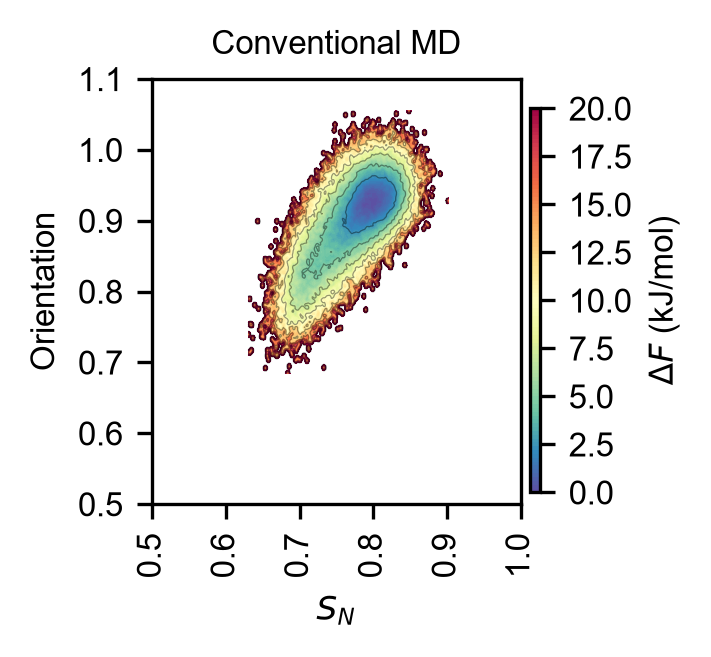

In [77]:
# -----------------------------
# Data preparation
# -----------------------------

df = colvar_conv.copy()
df = df[df["time"] > 0]

Fmax = 20

var1 = "cmap_N_sum"
var2 = "orientation"

T = 300
BETA = 1/(KB*T)


# -----------------------------
# Figure setup
# -----------------------------

fig, ax = plt.subplots(
    1, 1,
    figsize=(4*cm2inch, 5*cm2inch),
    dpi=300,
    sharex=True,
    sharey=True
)

fig.subplots_adjust(
    left=0.08,
    right=0.86,
    bottom=0.18,
    top=0.90,
    wspace=0.1
)


pp = None


# -----------------------------
# Calculate and plot FES
# -----------------------------
cv1 = df[var1].to_numpy()
cv2 = df[var2].to_numpy()

cv = np.vstack([cv1, cv2])

fes, grid, bounds, error = compute_fes(
    cv.T,
    weights=None,
    blocks=1,
    kbt=KB*T,
    bandwidth=0.005,
    scale_by="range",
    plot=False,
    plot_max_fes=100,
    eps=1e-10,
    backend="KDEpy",
)


extent = [item for sublist in bounds for item in sublist]


pp = ax.contourf(
    fes,
    extent=extent,
    levels=np.linspace(0, Fmax,101),
    cmap="Spectral_r"
)


# contour lines
ax.contour(
    fes,
    extent=extent,
    levels=np.linspace(0, Fmax + 1, 10),
    colors="black",
    linewidths=0.3,
    alpha=0.4
)

ax.set_title(f"Conventional MD",)

ax.set_xlabel(r"Z (nm)", )
ax.set_xlabel(r"$S_{N}$", )

ax.set_ylabel(r"Orientation", )


ax.tick_params(
    direction="out",
    top=False,
    left=True,
    right=False,
    # length=4,
    # width=1
)


# -----------------------------
# Shared colorbar
# -----------------------------

cbar_ax = fig.add_axes([0.88, 0.20, 0.02, 0.65])

cbar = fig.colorbar(
    pp,
    cax=cbar_ax
)
cbar.set_ticks(np.linspace(0,Fmax, 9))


cbar.set_label(
    "$\Delta F$ (kJ/mol)",
)


# -----------------------------
# Axis limits
# -----------------------------
ax.set_xlim(0.5, 1.0)
ax.set_ylim(0.5, 1.0)
ax.set_xticks(np.arange(0.5, 1.01, 0.10))
ax.set_yticks(np.arange(0.5, 1.1, 0.1))
ax.tick_params(axis='x', labelrotation=90)

# -----------------------------
# Save figure
# -----------------------------

plt.savefig(
    "images/2D_FES_cmap_N_sum_orientation_conventional_v2.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

### 2D FES from Reweighting distance R/Z FES

In [11]:
def plot_FES_and_scatter(data, colvar, 
                         var1,var2, 
                         bin1=100, bin2=100, 
                         level_min = 0, level_max = 20, 
                         step_n_lines = 20, 
                         step_n_colors = 20, 
                         
                         ax = None):
    bin1=bin1+1 
    bin2=bin2+1 
    alpha = np.array(data[var1]).reshape( bin1, bin2)
    comb_bonds = np.array(data[var2]).reshape( bin1, bin2)
    fes = np.array(data["file.free"]).reshape( bin1, bin2)
    fes = fes#*0.239006 #kJ to kkal
    #plot
    if ax != None:
        ax.contour(alpha, comb_bonds, fes, levels=np.linspace(level_min,level_max,step_n_lines), linewidths=0.5, colors='k')
        cntr = ax.contourf(alpha, comb_bonds, fes, levels=np.linspace(level_min,level_max, step_n_colors), cmap=cm.Spectral_r)

    else:
        plt.contour(alpha, comb_bonds, fes, levels=np.linspace(level_min,level_max,step_n_lines), linewidths=0.5, colors='k')
        cntr = plt.contourf(alpha, comb_bonds, fes, levels=np.linspace(level_min,level_max, step_n_colors), cmap=cm.Spectral_r)
                
        plt.colorbar(cntr, label="FES [kJ/mol]")
        plt.xlabel(var1)
        plt.ylabel(var2)
    
    # plt.show()
    return cntr

In [ ]:
import subprocess
from pathlib import Path

script = Path("scripts") / "FES_from_Reweighting.py"
var1 = 'poa_d.proj'
var2 = 'poa_d.ext'
bin1=100
bin2=100


for i,folder_i in enumerate([10,11,12,13]):

    colvar = Path(path_folding) / str(folder_i) / "0" / "COLVAR.0"

    import sys

    cmd = [
        sys.executable,
        str(script),
        "--bias", "opes1.bias",
        "--colvar", str(colvar),
        "--outfile", f"{folder_i}_FES_{var1}_{var2}",
        "--cv", f"{var1},{var2}",
        "--temp", "300",
        "-s", "0.0225,0.0125",
        "--bin", f"{bin1},{bin2}",
        "--blocks", "1",
        "--min", "0.0,0",
        "--max", "4.5,2.5",
    ]

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

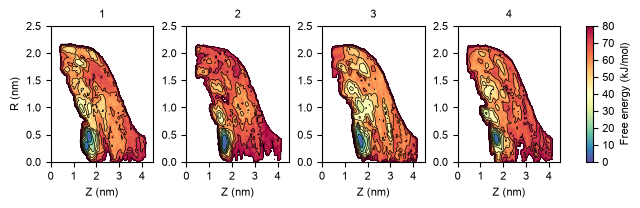

In [ ]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(16*cm2inch, 5*cm2inch),
    constrained_layout=True,
)
for i, folder_i in enumerate([10, 11, 12, 13]):

    data = load_dataframe(f"{folder_i}_FES_{var1}_{var2}")

    mappable = plot_FES_and_scatter(
        data,
        colvar,
        var1,
        var2,
        bin1=bin1,
        bin2=bin2,
        level_min=0,
        level_max=80,
        step_n_lines=10,
        step_n_colors=101,
        ax=axes[i],
    )

    axes[i].set_title(f"{i+1}")
    axes[i].set_xlabel("Z (nm)")

    if i == 0:
        axes[i].set_ylabel("R (nm)")

for ax in axes:
    ax.set_xlim(0, 4.5)
    ax.set_ylim(0.0, 2.5)
    ax.set_xticks(np.arange(0, 4.6, 1.0))
    ax.set_yticks(np.arange(0.0, 2.51, 0.5))
    ax.tick_params(direction="out")

# Shared colorbar

cbar = fig.colorbar(
    mappable,
    ax=axes,
    location="right",
)

cbar.set_label("Free energy (kJ/mol)")
cbar.set_ticks(np.arange(0, 81, 10))


plt.savefig(
    "images/2D_FES_distanceRZ_reweighting.png",
    dpi=600,
)

plt.show()

### 2D FES from Reweighting distance cmapN/cmapF FES

In [ ]:
script = Path("scripts") / "FES_from_Reweighting.py"
var1 = 'cmap_N_sum'
var2 = 'cmap_F_sum'
bin1=100
bin2=100


for i,folder_i in enumerate([10,11,12,13]):

    colvar = Path(path_folding) / str(folder_i) / "0" / "COLVAR.0"

    import sys

    cmd = [
        sys.executable,
        str(script),
        "--bias", "opes1.bias",
        "--colvar", str(colvar),
        "--outfile", f"{folder_i}_FES_{var1}_{var2}",
        "--cv", f"{var1},{var2}",
        "--temp", "300",
        "-s", "0.005,0.005",
        "--bin", f"{bin1},{bin2}",
        "--blocks", "1",
        "--min", "0.0,0",
        "--max", "1.0,1.0",
    ]

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

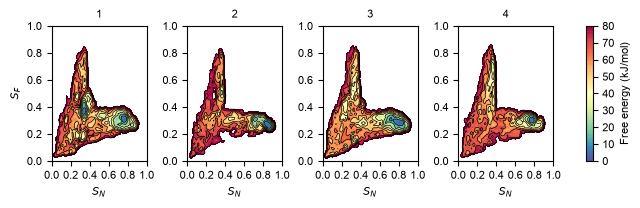

In [233]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(16*cm2inch, 5*cm2inch),
    constrained_layout=True,
)
for i, folder_i in enumerate([10, 11, 12, 13]):

    data = load_dataframe(f"{folder_i}_FES_{var1}_{var2}")

    mappable = plot_FES_and_scatter(
        data,
        colvar,
        var1,
        var2,
        bin1=bin1,
        bin2=bin2,
        level_min=0,
        level_max=80,
        step_n_lines=10,
        step_n_colors=101,
        ax=axes[i],
    )

    axes[i].set_title(f"{i+1}")
    axes[i].set_xlabel(r"$S_{N}$", )

    if i == 0:
        axes[i].set_ylabel(r"$S_{F}$",)

for ax in axes:
    ax.set_xlim(0, 1.0)
    ax.set_ylim(0.0, 1.0)
    ax.set_xticks(np.arange(0, 1.01, 0.2))
    ax.set_yticks(np.arange(0.0, 1.01, 0.2))
    ax.tick_params(direction="out")

# Shared colorbar

cbar = fig.colorbar(
    mappable,
    ax=axes,
    location="right",
)

cbar.set_label("Free energy (kJ/mol)")
cbar.set_ticks(np.arange(0, 81, 10))


plt.savefig(
    "images/2D_FES_cmapN_cmapF_reweighting.png",
    dpi=600,
)

plt.show()

### 2D FES from Reweighting distance orientation/Z FES

In [9]:
import subprocess
from pathlib import Path

script = Path("scripts") / "FES_from_Reweighting.py"
var1 = 'poa_d.proj'
var2 = 'orientation'
bin1=100
bin2=100


for i,folder_i in enumerate([10,11,12,13]):

    colvar = Path(path_folding) / str(folder_i) / "0" / "COLVAR.0"

    import sys

    cmd = [
        sys.executable,
        str(script),
        "--bias", "opes1.bias",
        "--colvar", str(colvar),
        "--outfile", f"{folder_i}_FES_{var1}_{var2}",
        "--cv", f"{var1},{var2}",
        "--temp", "300",
        "-s", "0.0225,0.01",
        "--bin", f"{bin1},{bin2}",
        "--blocks", "1",
        "--min", "0.0,-1.0",
        "--max", "4.5,1.0",
    ]

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

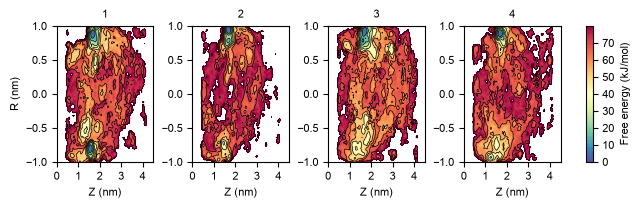

In [16]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(16*cm2inch, 5*cm2inch),
    constrained_layout=True,
)
for i, folder_i in enumerate([10, 11, 12, 13]):

    data = load_dataframe(f"{folder_i}_FES_{var1}_{var2}")

    mappable = plot_FES_and_scatter(
        data,
        colvar,
        var1,
        var2,
        bin1=bin1,
        bin2=bin2,
        level_min=0,
        level_max=80,
        step_n_lines=10,
        step_n_colors=101,
        ax=axes[i],
    )

    axes[i].set_title(f"{i+1}")
    axes[i].set_xlabel("Z (nm)")

    if i == 0:
        axes[i].set_ylabel("R (nm)")

for ax in axes:
    ax.set_xlim(0, 4.5)
    ax.set_ylim(-1.0, 1.0)
    ax.set_xticks(np.arange(0, 4.6, 1.0))
    ax.set_yticks(np.arange(-1.0, 1.1, 0.5))
    ax.tick_params(direction="out")

# Shared colorbar

cbar = fig.colorbar(
    mappable,
    ax=axes,
    location="right",
)

cbar.set_label("Free energy (kJ/mol)")
cbar.set_ticks(np.arange(0, 80, 10))


plt.savefig(
    "images/2D_FES_orientationZ_reweighting.png",
    dpi=600,
)

plt.show()

### 2D FES from Reweighting distance alpha/cmapN FES

In [79]:
path_folding

'C:/Users/vacaa/Documents/REPORTS/170/data/Binding'

In [80]:
script = Path("scripts") / "FES_from_Reweighting.py"
var1 = 'cmap_N_sum'
var2 = 'alpha'
bin1=100
bin2=100


for i,folder_i in enumerate([10,11,12,13]):

    colvar = Path(path_folding) / str(folder_i) / "0" / "COLVAR.0"

    import sys

    cmd = [
        sys.executable,
        str(script),
        "--bias", "opes1.bias",
        "--colvar", str(colvar),
        "--outfile", f"{folder_i}_FES_{var1}_{var2}",
        "--cv", f"{var1},{var2}",
        "--temp", "300",
        "-s", "0.005,0.005",
        "--bin", f"{bin1},{bin2}",
        "--blocks", "1",
        "--min", "0.0,0",
        "--max", "1.0,15.0",
    ]

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

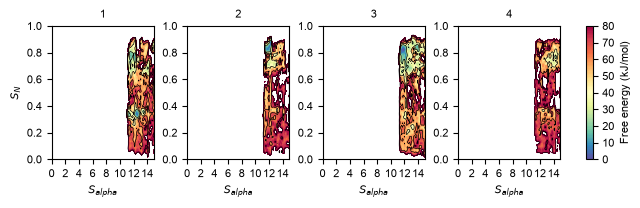

In [81]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(16*cm2inch, 5*cm2inch),
    constrained_layout=True,
)
for i, folder_i in enumerate([10, 11, 12, 13]):

    data = load_dataframe(f"{folder_i}_FES_{var1}_{var2}")

    mappable = plot_FES_and_scatter(
        data,
        colvar,
        var2,
        var1,
        bin1=bin2,
        bin2=bin1,
        level_min=0,
        level_max=80,
        step_n_lines=5,
        step_n_colors=101,
        ax=axes[i],
    )

    axes[i].set_title(f"{i+1}")
    axes[i].set_xlabel(r"$S_{alpha}$", )

    if i == 0:
        axes[i].set_ylabel(r"$S_{N}$",)

for ax in axes:
    ax.set_xlim(0, 15.0)
    ax.set_ylim(0.0, 1.0)
    ax.set_xticks(np.arange(0, 15.1, 2))
    ax.set_yticks(np.arange(0.0, 1.01, 0.2))
    ax.tick_params(direction="out")

# Shared colorbar

cbar = fig.colorbar(
    mappable,
    ax=axes,
    location="right",
)

cbar.set_label("Free energy (kJ/mol)")
cbar.set_ticks(np.arange(0, 81, 10))


plt.savefig(
    "images/2D_FES_alpha_cmapN_reweighting.png",
    dpi=600,
)

plt.show()

### Representative trajectory

In [8]:
# =============================================================================
# Parameters
# =============================================================================

n_bins = 20
repeat = 1
replica = 0
stride = 50

# =============================================================================
# Paths
# =============================================================================

path_folding = r"C:/Users/vacaa/Documents/REPORTS/170/data/Binding"

traj = md.load(
    f"{path_folding}/10/0/1onv.xtc",
    top=f"{path_folding}/10/0/1onv_prot.pdb"
)

# =============================================================================
# Select relevant COLVAR data
# =============================================================================

df = colvar[
    (colvar["Repeat"] == repeat) &
    (colvar["Replica"] == replica)
].iloc[::stride].copy()

df = df.reset_index(drop=True)

# =============================================================================
# Check trajectory / COLVAR correspondence
# =============================================================================

if len(df) != traj.n_frames:
    raise ValueError(
        f"Mismatch between COLVAR and trajectory:\n"
        f"COLVAR frames after stride = {len(df)}\n"
        f"Trajectory frames            = {traj.n_frames}\n\n"
        f"Check the stride and trajectory."
    )

# The rows of df now correspond to trajectory frames
df["frame"] = np.arange(len(df))

# =============================================================================
# Calculate OPES weights
# =============================================================================

bias = df["opes1.bias"].to_numpy()

logweights = BETA * (bias - np.max(bias))

weights = np.exp(logweights)

# Normalize
weights /= np.sum(weights)

df["weight"] = weights

# =============================================================================
# Divide poa_d.proj into 20 bins
# =============================================================================

poa_min = df["poa_d.proj"].min()
poa_max = df["poa_d.proj"].max()

bins = np.linspace(
    poa_min,
    poa_max,
    n_bins + 1
)

# Assign every frame to a bin
df["bin"] = pd.cut(
    df["poa_d.proj"],
    bins=bins,
    labels=False,
    include_lowest=True
)

# =============================================================================
# Select representative frame from each bin
# =============================================================================

representatives = []

for i in range(n_bins):

    bin_df = df[df["bin"] == i]

    if len(bin_df) == 0:
        print(f"Bin {i + 1}: EMPTY")
        continue

    # Frame with maximum statistical weight
    representative = bin_df.loc[
        bin_df["weight"].idxmax()
    ]

    representatives.append(representative)

    print(
        f"Bin {i + 1:2d}: "
        f"POA = {representative['poa_d.proj']:.4f}, "
        f"bias = {representative['opes1.bias']:.4f}, "
        f"weight = {representative['weight']:.6e}, "
        f"frame = {int(representative['frame'])}"
    )

# Convert representatives to DataFrame
representatives = pd.DataFrame(representatives)

# =============================================================================
# Sort representatives according to poa_d.proj
# =============================================================================

representatives = (
    representatives
    .sort_values("poa_d.proj")
    .reset_index(drop=True)
)

# =============================================================================
# Extract representative trajectory frames
# =============================================================================

frame_indices = representatives["frame"].astype(int).to_numpy()

traj_representative = traj[frame_indices]

# =============================================================================
# Save representative trajectory
# =============================================================================

traj_representative.save_xtc(
    f"{path_folding}/10/0/representative_20frames.xtc"
)

# Save information about selected frames
representatives.to_csv(
    f"{path_folding}/10/0/representative_20frames.csv",
    index=False
)

print("\nRepresentative trajectory created.")
print(f"Selected frames: {len(frame_indices)}")

Bin  1: POA = 0.5875, bias = 30.7081, weight = 2.652590e-10, frame = 4928
Bin  2: POA = 0.7737, bias = 39.2721, weight = 8.218204e-09, frame = 4931
Bin  3: POA = 0.9702, bias = 34.7345, weight = 1.332638e-09, frame = 4932
Bin  4: POA = 1.1640, bias = 46.1618, weight = 1.301192e-07, frame = 999
Bin  5: POA = 1.3396, bias = 49.7423, weight = 5.467192e-07, frame = 3433
Bin  6: POA = 1.5294, bias = 78.2689, weight = 5.065082e-02, frame = 3546
Bin  7: POA = 1.6996, bias = 83.9443, weight = 4.928682e-01, frame = 1895
Bin  8: POA = 1.7851, bias = 70.6367, weight = 2.375332e-03, frame = 1894
Bin  9: POA = 1.9529, bias = 57.3745, weight = 1.165775e-05, frame = 2304
Bin 10: POA = 2.2247, bias = 38.8619, weight = 6.971938e-09, frame = 3560
Bin 11: POA = 2.3000, bias = 34.0652, weight = 1.019005e-09, frame = 3581
Bin 12: POA = 2.6544, bias = 30.1172, weight = 2.093075e-10, frame = 3196
Bin 13: POA = 2.7153, bias = 30.4895, weight = 2.430074e-10, frame = 4343
Bin 14: POA = 2.9133, bias = 32.6398, w

### Binding mechanism. Native state.

In [41]:
path_folding = r'C:\Users\vacaa\Documents\REPORTS\170\data\Binding'
repeat, replica, stride = 13, 0, 50
native_contacts_pairs = ['493-953','474-953','490-953','513-957','497-957','470-953','502-957','478-949','489-949','486-949','501-960','498-956','471-947','471-954','504-958']
flipped_contacts_pairs = ['474-960','490-961','490-960','490-957','513-949','497-953','513-953','498-954','510-959','504-948','504-945','498-947']

contacts_pairs = flipped_contacts_pairs

# C-map data
cmap = load_dataframe(
    f'{path_folding}/{repeat}/0/COLVAR_CMAP_RERUN'
).iloc[::].reset_index(drop=True)

contact_columns = [
    c for c in cmap.columns
    if c.startswith("cmap_F")
]

# CV + bias data
df = colvar[
    (colvar["Repeat"] == repeat - 9) &
    (colvar["Replica"] == replica)
].iloc[::stride].reset_index(drop=True)

if len(df) != len(cmap):
    raise ValueError(f"Frame mismatch: {len(df)} vs {len(cmap)}")

cmap_sum = df["poa_d.proj"].to_numpy(float)
contacts = cmap[contact_columns].to_numpy(float)

# OPES weights
bias = df["opes1.bias"].to_numpy(float)
weights = np.exp(BETA * (bias - np.nanmax(bias)))

# Distance bins
bins = np.arange(0.5, 4.5, 0.25)

contact_probabilities = np.full(
    (len(bins) - 1, len(contact_columns)), np.nan
)

for i, (lo, hi) in enumerate(zip(bins[:-1], bins[1:])):
    mask = (cmap_sum >= lo) & (cmap_sum < hi)
    if mask.any():
        w = weights[mask]
        contact_probabilities[i] = np.average(
            contacts[mask], axis=0, weights=w
        )
    print(f"cmap_N_sum = {lo:g}-{hi:g}: {mask.sum()} frames")

print("Shape:", contact_probabilities.shape)

cmap_N_sum = 0.5-0.75: 244 frames
cmap_N_sum = 0.75-1: 377 frames
cmap_N_sum = 1-1.25: 537 frames
cmap_N_sum = 1.25-1.5: 602 frames
cmap_N_sum = 1.5-1.75: 804 frames
cmap_N_sum = 1.75-2: 731 frames
cmap_N_sum = 2-2.25: 517 frames
cmap_N_sum = 2.25-2.5: 335 frames
cmap_N_sum = 2.5-2.75: 271 frames
cmap_N_sum = 2.75-3: 187 frames
cmap_N_sum = 3-3.25: 136 frames
cmap_N_sum = 3.25-3.5: 86 frames
cmap_N_sum = 3.5-3.75: 54 frames
cmap_N_sum = 3.75-4: 31 frames
cmap_N_sum = 4-4.25: 22 frames
Shape: (15, 12)


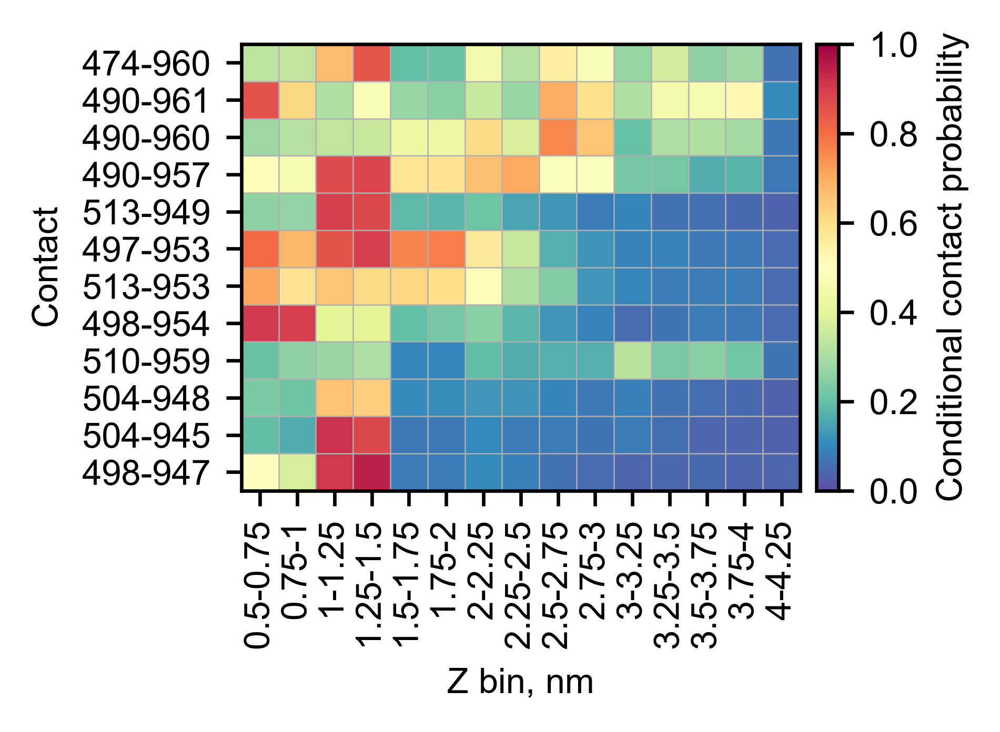

In [42]:
fig, ax = plt.subplots(
    figsize=(9 * cm2inch, 6 * cm2inch),
    dpi=600
)

im = ax.imshow(
    contact_probabilities.T,
    cmap="Spectral_r",
    vmin=0,
    vmax=1,
    aspect="equal",
    interpolation="nearest"
)

# ------------------------------------------------------------
# Grid lines between cells
# ------------------------------------------------------------

ax.set_xticks(
    np.arange(-0.5, len(bins) - 1, 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, len(contact_columns), 1),
    minor=True
)

ax.grid(
    which="minor",
    linewidth=0.3
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# ------------------------------------------------------------
# Tick labels
# ------------------------------------------------------------

ax.set_xticks(
    np.arange(len(bins) - 1)
)

ax.set_xticklabels(
    [f"{lo:g}-{hi:g}" for lo, hi in zip(bins[:-1], bins[1:])],
    rotation=90
)

ax.set_yticks(
    np.arange(len(contact_columns))
)

ax.set_yticklabels(
    contacts_pairs
)

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel(r"Z bin, nm")
ax.set_ylabel("Contact")

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    pad=0.02
)

cbar.set_label(
    "Conditional contact probability"
)

cbar.set_ticks(
    np.arange(0, 1.01, 0.2)
)

cbar.outline.set_edgecolor("black")
cbar.outline.set_linewidth(0.8)

# ------------------------------------------------------------

plt.tight_layout()

plt.savefig(
    f"images/Binned_F_contact_probability_along_Z_OPES_repeat_{repeat}.png",
    dpi=600,
)

plt.show()

## Folding-upon-binding

### Load the data

In [105]:
# OneOPES MD
colvar_list = []
path_folding = r'C:/Users/vacaa/Documents/REPORTS/170/data/Folding_and_binding/OneOPES'

for i,j in enumerate([1,2,3,4]):
    for k in range(8):
        colvar = load_dataframe(f'{path_folding}/{j}/{k}/COLVAR.{k}')
        colvar_list.append(colvar)
        colvar['Replica'] = [k]*len(colvar)
        colvar['Repeat'] = [i+1]*len(colvar)
    

colvar = pd.concat(colvar_list)
colvar['radius'] = np.sqrt(colvar['poa_d.proj']**2 + colvar['poa_d.ext']**2)
colvar.replace(np.nan, 0, inplace=True)
colvar['bias_sum'] = np.sum(colvar[['opes1.bias','opes2.bias','opesX.bias']].to_numpy(), axis = 1)
colvar['bias_sum_all'] = np.sum(colvar.filter(like='.bias').to_numpy(), axis = 1)
colvar['time']/=1000

#Conventional MD
path_folding = r'C:/Users/vacaa/Documents/REPORTS/170/data/Binding/20_nobias/1'

colvar_conv = load_dataframe(f'{path_folding}/COLVAR_RERUN')
colvar_conv['time']/= 10 #ns
colvar_conv["Time (us)"] = colvar_conv['time'] / 1000

colvar_conv.columns
colvar_conv.head()


path_folding = r'C:/Users/vacaa/Documents/REPORTS/170/data/Folding_and_binding/OneOPES'

### Distance and bias over the time

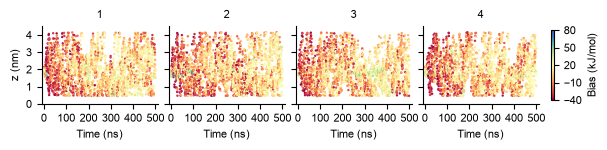

In [7]:
df = colvar[::100]
df = df[df["Replica"] == 1]

data_Y = "cmap_F_sum"
data_Y = "poa_d.proj"

def scatter(data, **kwargs):
    plt.scatter(
        data["time"],
        data[data_Y],
        c=data["opes1.bias"],
        cmap="Spectral",
        norm=mpl.colors.Normalize(*(-50, 80)),   # same style as hue_norm=(-10,20)
        s=3,
        linewidths=0,
    )

g = sns.FacetGrid(
    df,
    col="Repeat",
    margin_titles=False,
    height=1,
    aspect=2,
)

g.map_dataframe(scatter)

# Shared colorbar
sm = mpl.cm.ScalarMappable(
    cmap="Spectral",
    norm=mpl.colors.Normalize(*(-40, 80))
)
sm.set_array([])

cbar = g.fig.colorbar(
    sm,
    ax=g.axes,
    label="Bias (kJ/mol)",
    pad=0.02,
    shrink=0.9,
)
cbar.set_ticks(np.linspace(-40,80,5))

g.set(
    xlim=(-10, 510),
    ylim=(0, 4.5),
)
# More ticks
for ax in g.axes.flat:
    ax.set_xticks(np.arange(0, 501, 100))
    ax.set_yticks(np.arange(0, 1.1, 0.2))
    ax.set_yticks(np.arange(0, 4.5, 1.0))

g.set_titles(template="{col_name}", size=8)
g.fig.set_size_inches(16*cm2inch, 5*cm2inch)

g.set_axis_labels("Time (ns)", "z (nm)")
# g.set_axis_labels("Time (ns)", "S$_{F}$")

plt.savefig(f'images/FB_{data_Y}_time_hue_bias.png', dpi = 600, bbox_inches="tight")

plt.show()

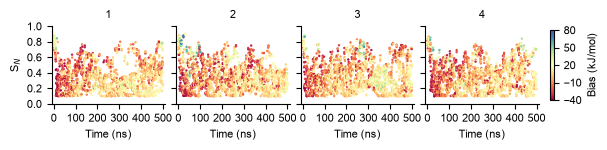

In [24]:
df = colvar[::100]
df = df[df["Replica"] == 1]

data_Y = "cmap_N_sum"
# data_Y = "poa_d.proj"

def scatter(data, **kwargs):
    plt.scatter(
        data["time"],
        data[data_Y],
        c=data["opes1.bias"],
        cmap="Spectral",
        norm=mpl.colors.Normalize(*(-50, 80)),   # same style as hue_norm=(-10,20)
        s=3,
        linewidths=0,
    )

g = sns.FacetGrid(
    df,
    col="Repeat",
    margin_titles=False,
    height=1,
    aspect=2,
)

g.map_dataframe(scatter)

# Shared colorbar
sm = mpl.cm.ScalarMappable(
    cmap="Spectral",
    norm=mpl.colors.Normalize(*(-40, 80))
)
sm.set_array([])

cbar = g.fig.colorbar(
    sm,
    ax=g.axes,
    label="Bias (kJ/mol)",
    pad=0.02,
    shrink=0.9,
)
cbar.set_ticks(np.linspace(-40,80,5))

g.set(
    xlim=(-10, 510),
    ylim=(0, 4.5),
)
g.set(
    xlim=(-10, 510),
    ylim=(0, 1),
)

# More ticks
for ax in g.axes.flat:
    ax.set_xticks(np.arange(0, 501, 100))
    ax.set_yticks(np.arange(0, 1.1, 0.2))
    # ax.set_yticks(np.arange(0, 4.5, 1.0))

g.set_titles(template="{col_name}", size=8)
g.fig.set_size_inches(16*cm2inch, 5*cm2inch)

g.set_axis_labels("Time (ns)", "z (nm)")
g.set_axis_labels("Time (ns)", "S$_{N}$")

plt.savefig(f'images/FB_{data_Y}_time_hue_bias.png', dpi = 600, bbox_inches="tight")

plt.show()

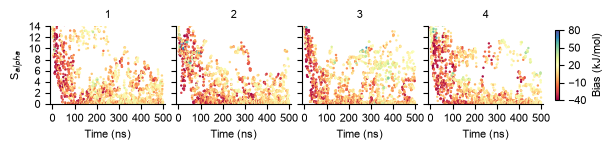

In [69]:
df = colvar[::100]
df = df[df["Replica"] == 1]

data_Y = "alpha"
# data_Y = "poa_d.proj"

def scatter(data, **kwargs):
    plt.scatter(
        data["time"],
        data[data_Y],
        c=data["opes1.bias"],
        cmap="Spectral",
        norm=mpl.colors.Normalize(*(-50, 80)),   # same style as hue_norm=(-10,20)
        s=3,
        linewidths=0,
    )

g = sns.FacetGrid(
    df,
    col="Repeat",
    margin_titles=False,
    height=1,
    aspect=2,
)

g.map_dataframe(scatter)

# Shared colorbar
sm = mpl.cm.ScalarMappable(
    cmap="Spectral",
    norm=mpl.colors.Normalize(*(-40, 80))
)
sm.set_array([])

cbar = g.fig.colorbar(
    sm,
    ax=g.axes,
    label="Bias (kJ/mol)",
    pad=0.02,
    shrink=0.9,
)
cbar.set_ticks(np.linspace(-40,80,5))

g.set(
    xlim=(-10, 510),
    ylim=(0, 14),
)

# More ticks
for ax in g.axes.flat:
    ax.set_xticks(np.arange(0, 501, 100))
    ax.set_yticks(np.arange(0, 15, 2))
    # ax.set_yticks(np.arange(0, 4.5, 1.0))

g.set_titles(template="{col_name}", size=8)
g.fig.set_size_inches(16*cm2inch, 5*cm2inch)

g.set_axis_labels("Time (ns)", "z (nm)")
g.set_axis_labels("Time (ns)", "S$_{alpha}$")

plt.savefig(f'images/FB_{data_Y}_time_hue_bias.png', dpi = 600, bbox_inches="tight")

plt.show()

In [ ]:
df = colvar[::100]
df = df[df["Replica"] == 1]

# data_Y = "cmap_F_sum"
data_X = 'poa_d.proj'
data_Y = "cmap_N_sum"

def scatter(data, **kwargs):
    plt.scatter(
        data[data_X],
        data[data_Y],
        c=data["opes1.bias"],
        cmap="Spectral",
        norm=mpl.colors.Normalize(*(-50, 80)),   # same style as hue_norm=(-10,20)
        s=3,
        linewidths=0,
    )

g = sns.FacetGrid(
    df,
    col="Repeat",
    margin_titles=False,
    height=1,
    aspect=2,
)

g.map_dataframe(scatter)

# Shared colorbar
sm = mpl.cm.ScalarMappable(
    cmap="Spectral",
    norm=mpl.colors.Normalize(*(-40, 80))
)
sm.set_array([])

cbar = g.fig.colorbar(
    sm,
    ax=g.axes,
    label="Bias (kJ/mol)",
    pad=0.02,
    shrink=0.9,
)
cbar.set_ticks(np.linspace(-40,80,5))

g.set(
    xlim=(0.0, 4.5),
    ylim=(0, 1.),
)
# More ticks
for ax in g.axes.flat:
    ax.set_xticks(np.arange(0, 4.5, 1.0))
    ax.set_yticks(np.arange(0, 1.1, 0.2))

g.set_titles(template="{col_name}", size=8)
g.fig.set_size_inches(16*cm2inch, 5*cm2inch)

# g.set_axis_labels("Time (ns)", "z (nm)")
g.set_axis_labels("z (nm)", "S$_{N}$")

plt.savefig(f'images/FB_{data_Y}_{data_X}_hue_bias_v2.png', dpi = 600, bbox_inches="tight")

plt.show()

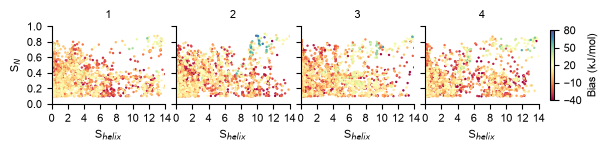

In [65]:
df = colvar[::100]
df = df[df["Replica"] == 1]

# data_Y = "cmap_F_sum"
data_X = 'alpha'
data_Y = "cmap_N_sum"

def scatter(data, **kwargs):
    plt.scatter(
        data[data_X],
        data[data_Y],
        c=data["opes1.bias"],
        cmap="Spectral",
        norm=mpl.colors.Normalize(*(-50, 80)),   # same style as hue_norm=(-10,20)
        s=3,
        linewidths=0,
    )

g = sns.FacetGrid(
    df,
    col="Repeat",
    margin_titles=False,
    height=1,
    aspect=2,
)

g.map_dataframe(scatter)

# Shared colorbar
sm = mpl.cm.ScalarMappable(
    cmap="Spectral",
    norm=mpl.colors.Normalize(*(-40, 80))
)
sm.set_array([])

cbar = g.fig.colorbar(
    sm,
    ax=g.axes,
    label="Bias (kJ/mol)",
    pad=0.02,
    shrink=0.9,
)
cbar.set_ticks(np.linspace(-40,80,5))

g.set(
    xlim=(0.0, 14),
    ylim=(0, 1.),
)
# More ticks
for ax in g.axes.flat:
    ax.set_xticks(np.arange(0, 15.1, 2.0))
    ax.set_yticks(np.arange(0, 1.1, 0.2))

g.set_titles(template="{col_name}", size=8)
g.fig.set_size_inches(16*cm2inch, 5*cm2inch)

# g.set_axis_labels("Time (ns)", "z (nm)")
g.set_axis_labels("S$_{helix}$", "S$_{N}$")

plt.savefig(f'images/FB_{data_Y}_{data_X}_hue_bias_v2.png', dpi = 600, bbox_inches="tight")

plt.show()

### Distance FES

<>:95: SyntaxWarning: invalid escape sequence '\D'
<>:95: SyntaxWarning: invalid escape sequence '\D'
C:\Users\vacaa\AppData\Local\Temp\ipykernel_24624\1236042114.py:95: SyntaxWarning: invalid escape sequence '\D'
  ax.set_ylabel("$\Delta F$ (kJ/mol)")


1
2
3
4


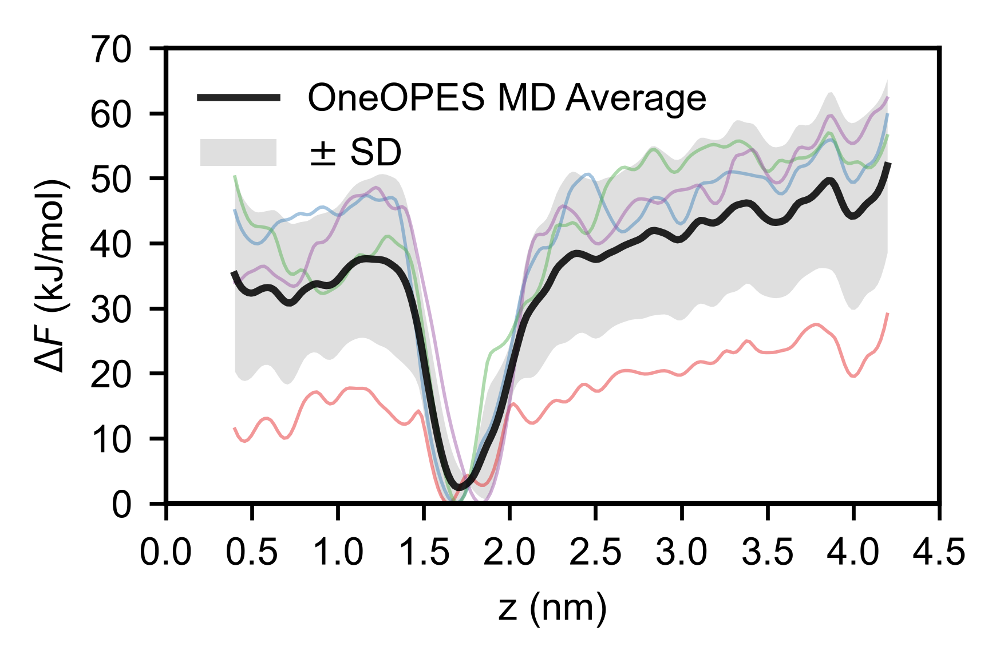

In [106]:
df = colvar[::1]
# df = df[df["Replica"] == 0]

T = 300
BETA = 1/(KB*T)

fes_list = []
grid_list = []

# Calculate FES for each repeat
for i in df["Repeat"].unique():
    print(i)
    data = df[df["Repeat"] == i]

    bias = data["bias_sum_all"].to_numpy()
    cv = data["poa_d.proj"].to_numpy()

    # numerically stable weights
    logweights = BETA * (bias - np.max(bias))
    w = np.exp(logweights)

    fes, grid, bounds, error = compute_fes(
        cv,
        weights=w,
        blocks=1,
        kbt=KB*T,
        bandwidth=0.01,
        scale_by="range",
        plot=False,
        plot_max_fes=100,
        eps=1e-10,
    )

    # normalize minimum to zero
    fes = fes - np.min(fes)

    fes_list.append(fes)
    grid_list.append(grid)


# Convert to arrays
fes_array = np.array(fes_list)
grid = grid_list[0]

# Mean and standard deviation
fes_mean = np.mean(fes_array, axis=0)
fes_std = np.std(fes_array, axis=0)


# ----------------------------
# Publication quality plotting
# ----------------------------

fig, ax = plt.subplots(
    figsize=(7.5*cm2inch, 5*cm2inch),
    dpi=600
)

colors = plt.cm.Set1(range(len(df["Repeat"].unique())))

# Individual repeats
for i, fes in enumerate(fes_array):
    ax.plot(
        grid,
        fes,
        color=colors[i],
        lw=0.7,
        alpha=0.45,
        # label=f"Repeat {i+1}"
    )

# Average FES
ax.plot(
    grid,
    fes_mean,
    color="black",
    lw=1.5,
    alpha=0.85,
    label="OneOPES MD Average"
)

# Standard deviation envelope
ax.fill_between(
    grid,
    fes_mean - fes_std,
    fes_mean + fes_std,
    color="gray",
    alpha=0.25,
    linewidth=0,
    label=r"$\pm$ SD"
)

# Labels and style
ax.set_xlabel("z (nm)")
ax.set_ylabel("$\Delta F$ (kJ/mol)")

ax.set_xlim(0, 4.5)
ax.set_ylim(0, 70)
ax.set_xticks(np.arange(0, 4.51, 0.5))
ax.set_yticks(np.arange(0, 71, 10))


ax.legend(
    frameon=False,
)

for spine in ax.spines.values():
    spine.set_linewidth(1)

plt.tight_layout()
plt.savefig('images/FB_Distance_FES_v3_all.png', dpi = 600)
plt.show()

### Convergence Plot

c:\Users\vacaa\Documents\REPORTS\170\Code\.venv\Lib\site-packages\numpy\_core\_methods.py:188: RuntimeWarning: invalid value encountered in subtract
  x = um.subtract(arr, arrmean, out=...)


Determined value: 32.83259385045743 ± 9.196311890126415


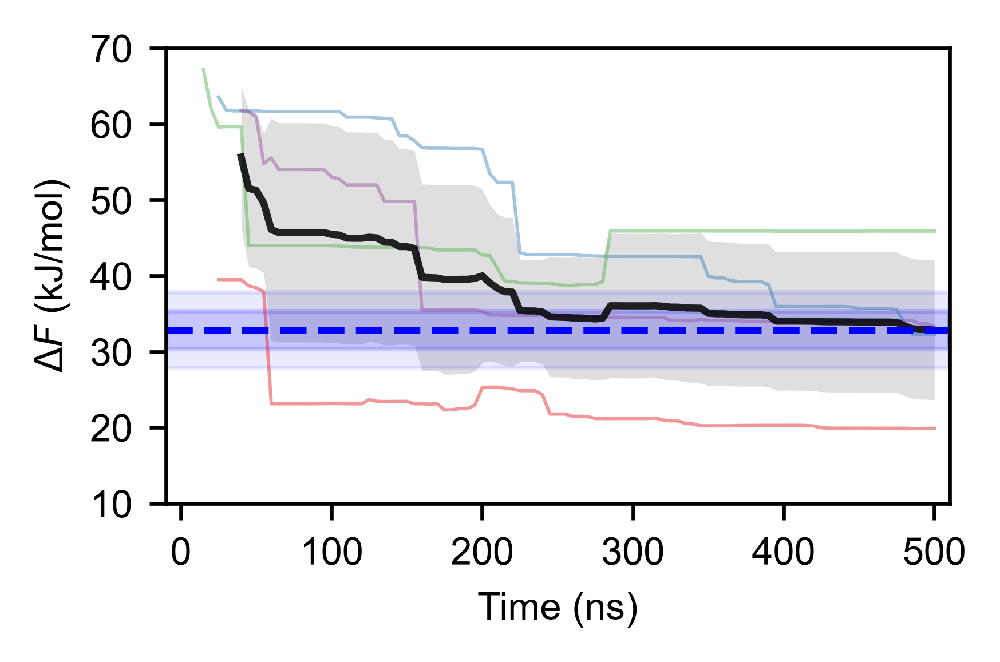

In [87]:

fragments = 100
time_min = 0

df = colvar[colvar["Replica"] == 0]

T = 300
BETA = 1/(KB*T)

time_max = df["time"].max()

# Store convergence curves
deltaF_all = []

for rep in df["Repeat"].unique()[:]:

    data_rep = df[df["Repeat"] == rep]

    deltaF_metad = np.empty(fragments)
    time_analyse = np.empty(fragments)

    for i in range(fragments):

        time_analyse[i] = (
            (time_max - time_min) / fragments * (i + 1)
            + time_min
        )

        data = data_rep[
            data_rep["time"].between(time_min, time_analyse[i])
        ]

        bias = data["bias_sum"].to_numpy()
        cv = data["poa_d.proj"].to_numpy()

        # stable weights
        logweights = BETA * (bias - np.max(bias))
        w = np.exp(logweights)

        fes, grid, bounds, error = compute_fes(
            cv,
            weights=w,
            blocks=1,
            kbt=KB*T,
            bandwidth=0.01,
            scale_by="range",
            plot=False,
            plot_max_fes=50,
            eps=1e-10,
        )

        # Define basin
        mask = np.full(fes.shape, True)
        mask[grid > 3.5] = False

        deltaF_metad[i] = calcDeltaF(
            fes,
            basinMask=mask,
            kbt=KBT
        )

    deltaF_all.append(deltaF_metad)


# Convert to array
deltaF_all = np.array(deltaF_all)

# Average and standard deviation
deltaF_mean = np.mean(deltaF_all, axis=0)
deltaF_std = np.std(deltaF_all, axis=0)


# --------------------------
# Plot
# --------------------------

fig, ax = plt.subplots(
    figsize=(7.5*cm2inch,5*cm2inch),
    dpi=600
)

colors = plt.cm.Set1(range(len(df["Repeat"].unique())))

# Individual repeats
for i, deltaF in enumerate(deltaF_all):
    ax.plot(
        time_analyse,
        deltaF,
        color=colors[i],
        lw=0.7,
        alpha=0.45,
        # label=f"Repeat {i+1}"
    )
    
# Average
ax.plot(
    time_analyse,
    deltaF_mean,
    color="black",
    lw=1.5,
    alpha=0.85,
    label="Average"
)

# Standard deviation
ax.fill_between(
    time_analyse,
    deltaF_mean - deltaF_std,
    deltaF_mean + deltaF_std,
    color="gray",
    alpha=0.25,
    linewidth=0,
    label="± SD"
)

# Last values
deltaF_final = deltaF_mean[-1]
ax.axhline(
    deltaF_final,
    color="blue",
    lw=1.5,
    linestyle="--",
    label=r"OneOPES MD $\Delta F_{\mathrm{final}}$"
)

ax.axhspan(
    deltaF_final - KBT,
    deltaF_final + KBT,
    color="blue",
    alpha=0.15,
    label=r"$\Delta F_{\mathrm{final}}\pm k_BT$"
)

ax.axhspan(
    deltaF_final - 2*KBT,
    deltaF_final + 2*KBT,
    color="blue",
    alpha=0.08,
    label=r"$\Delta F_{\mathrm{final}}\pm 2k_BT$"
)

# Cosmetics
ax.set_xlabel("Time (ns)")
ax.set_ylabel(r"$\Delta F$ (kJ/mol)")


# ax.legend(
#     frameon=False,
#     loc = 'lower right'
# )
plt.xlim(-10,510)
plt.ylim(10,70)
plt.yticks(np.arange(10, 71, 10))




plt.tight_layout()
print(f'Determined value: {deltaF_final} ± {deltaF_std[-1]}')
plt.savefig('images/FB_Convergence_distance_v1_0.png', dpi = 600)
plt.show()

### CMAP_N FES

<>:96: SyntaxWarning: invalid escape sequence '\D'
<>:96: SyntaxWarning: invalid escape sequence '\D'
C:\Users\vacaa\AppData\Local\Temp\ipykernel_24624\769463728.py:96: SyntaxWarning: invalid escape sequence '\D'
  ax.set_ylabel("$\Delta F$ (kJ/mol)")


1
2
3
4


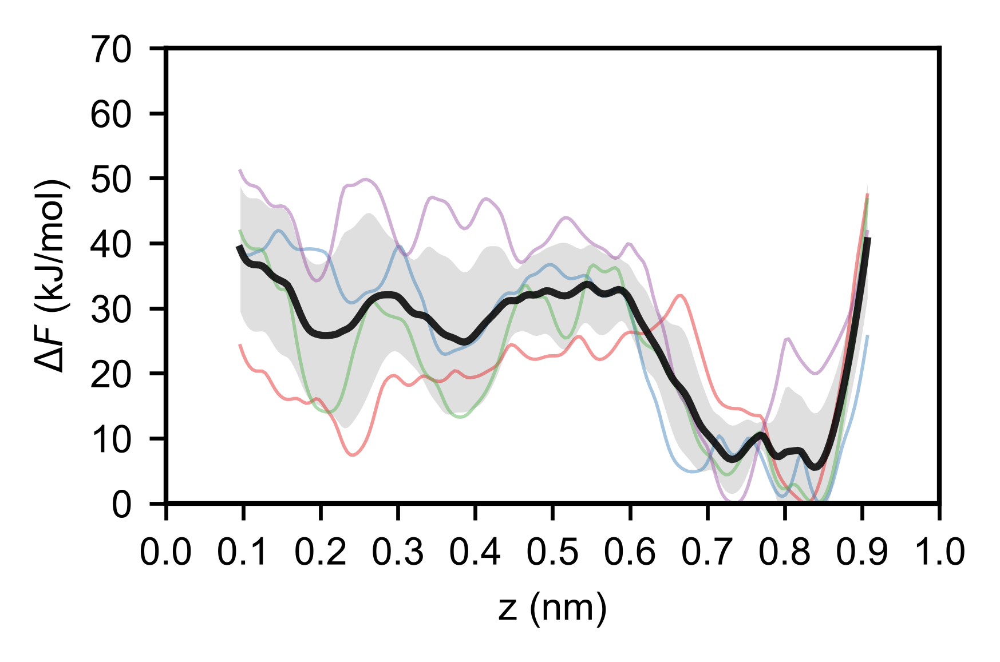

In [107]:
df = colvar[::1]
# df = df[df["Replica"] == 0]

T = 300
BETA = 1/(KB*T)

fes_list = []
grid_list = []

# Calculate FES for each repeat
for i in df["Repeat"].unique():
    print(i)
    data = df[df["Repeat"] == i]

    bias = data["bias_sum"].to_numpy()
    bias = data.loc[data["cmap_F_sum"] < 0.4, "bias_sum"].to_numpy()
    cv = data.loc[data["cmap_F_sum"] < 0.4, "cmap_N_sum"].to_numpy()

    # numerically stable weights
    logweights = BETA * (bias - np.max(bias))
    w = np.exp(logweights)

    fes, grid, bounds, error = compute_fes(
        cv,
        weights=w,
        blocks=1,
        kbt=KB*T,
        bandwidth=0.01,
        scale_by="range",
        plot=False,
        plot_max_fes=100,
        eps=1e-10,
    )

    # normalize minimum to zero
    fes = fes - np.min(fes)

    fes_list.append(fes)
    grid_list.append(grid)


# Convert to arrays
fes_array = np.array(fes_list)
grid = grid_list[0]

# Mean and standard deviation
fes_mean = np.mean(fes_array, axis=0)
fes_std = np.std(fes_array, axis=0)


# ----------------------------
# Publication quality plotting
# ----------------------------

fig, ax = plt.subplots(
    figsize=(7.5*cm2inch, 5*cm2inch),
    dpi=600
)

colors = plt.cm.Set1(range(len(df["Repeat"].unique())))

# Individual repeats
for i, fes in enumerate(fes_array):
    ax.plot(
        grid,
        fes,
        color=colors[i],
        lw=0.7,
        alpha=0.45,
        # label=f"Repeat {i+1}"
    )

# Average FES
ax.plot(
    grid,
    fes_mean,
    color="black",
    lw=1.5,
    alpha=0.85,
    label="OneOPES MD Average"
)

# Standard deviation envelope
ax.fill_between(
    grid,
    fes_mean - fes_std,
    fes_mean + fes_std,
    color="gray",
    alpha=0.25,
    linewidth=0,
    label=r"$\pm$ SD"
)

# Labels and style
ax.set_xlabel("z (nm)")
ax.set_ylabel("$\Delta F$ (kJ/mol)")

ax.set_xlim(0, 1.0)
ax.set_ylim(0, 70)
ax.set_xticks(np.arange(0, 1.01, 0.1))
ax.set_yticks(np.arange(0, 71, 10))


# ax.legend(
#     frameon=False,
# )

for spine in ax.spines.values():
    spine.set_linewidth(1)

plt.tight_layout()
plt.savefig('images/FB_cmap_N_FES_v2_all_no_legend.png', dpi = 600)
plt.show()

Repeat 1 excluded: Determined value: 37.14655115517004 ± 6.190473272142248

### 2D FES alpha CMAP N

In [ ]:
colvar

<>:131: SyntaxWarning: invalid escape sequence '\D'
<>:131: SyntaxWarning: invalid escape sequence '\D'
C:\Users\vacaa\AppData\Local\Temp\ipykernel_24624\1488443093.py:131: SyntaxWarning: invalid escape sequence '\D'
  "$\Delta F$ (kJ/mol)",


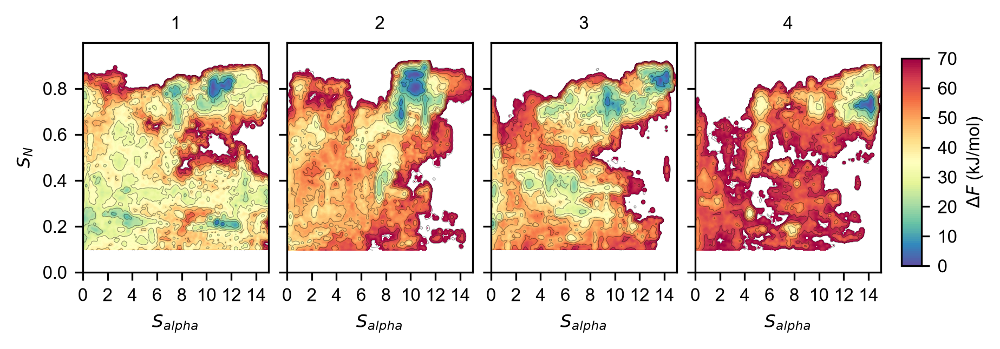

In [86]:
# -----------------------------
# Data preparation
# -----------------------------

df = colvar.copy()
# df = df[df["Replica"] == 0]
df = df[df["time"] > 0]

Fmax = 70

var1 = "alpha"
var2 = "cmap_N_sum"

T = 300
BETA = 1/(KB*T)


# -----------------------------
# Figure setup
# -----------------------------

fig, axes = plt.subplots(
    1, 4,
    figsize=(16*cm2inch, 5*cm2inch),
    dpi=300,
    sharex=True,
    sharey=True
)

fig.subplots_adjust(
    left=0.08,
    right=0.86,
    bottom=0.18,
    top=0.90,
    wspace=0.1
)


pp = None


# -----------------------------
# Calculate and plot FES
# -----------------------------
# axes = [axes]
for i, ax in enumerate(axes):
        
    data = df[df["Repeat"] == i+1]

    bias = data["opes1.bias"].to_numpy()

    cv1 = data[var1].to_numpy()
    cv2 = data[var2].to_numpy()

    cv = np.vstack([cv1, cv2])


    # weights
    logweights = BETA * (bias - np.max(bias))
    w = np.exp(logweights)
    w /= np.sum(w)


    fes, grid, bounds, error = compute_fes(
        cv.T,
        weights=w,
        blocks=1,
        kbt=KB*T,
        bandwidth=0.005,
        scale_by="range",
        plot=False,
        # bounds = [(np.float64(0.), np.float64(16.)), (np.float64(0.), np.float64(16.))],
        plot_max_fes=100,
        eps=1e-10,
        backend="KDEpy",
    )


    extent = [item for sublist in bounds for item in sublist]


    pp = ax.contourf(
        fes,
        extent=extent,
        levels=np.linspace(0, Fmax,101),
        cmap="Spectral_r"
    )


    # contour lines
    ax.contour(
        fes,
        extent=extent,
        levels=np.linspace(0, Fmax + 1, 10),
        colors="black",
        linewidths=0.3,
        alpha=0.4
    )

    ax.set_title(f"{i+1}",)    
    ax.set_xlabel(r"$S_{alpha}$", )

    if i == 0:
        ax.set_ylabel(r"$S_{N}$", )

    if i > 0:
        ax.tick_params(
            direction="out",
            top=False,
            left=True,
            right=False,
            # length=4,
            # width=1
        )


# -----------------------------
# Shared colorbar
# -----------------------------

cbar_ax = fig.add_axes([0.88, 0.20, 0.02, 0.65])

cbar = fig.colorbar(
    pp,
    cax=cbar_ax
)
cbar.set_ticks(np.linspace(0,Fmax,int(Fmax/10 + 1)))


cbar.set_label(
    "$\Delta F$ (kJ/mol)",
)


# -----------------------------
# Axis limits
# -----------------------------

for ax in axes:
    ax.set_xlim(0, 15)
    ax.set_ylim(0, 1)
    ax.set_xticks(np.arange(0, 15, 2))
    ax.set_yticks(np.arange(0, 1, 0.2))

# -----------------------------
# Save figure
# -----------------------------

# plt.savefig(
#     "images/FB_2D_FES_alpha_cmapN_all.png",
#     dpi=600,
#     bbox_inches="tight"
# )

plt.show()

In [ ]:
# -----------------------------
# Data preparation
# -----------------------------

df = colvar_conv.copy()
# df = df[df["Replica"] == 0]
df = df[df["time"] > 0]

Fmax = 20

var1 = "alpha"
var2 = "cmap_N_sum"

T = 300
BETA = 1/(KB*T)


# -----------------------------
# Figure setup
# -----------------------------

fig, axes = plt.subplots(
    1, 1,
    figsize=(4*cm2inch, 5*cm2inch),
    dpi=300,
    sharex=True,
    sharey=True
)

fig.subplots_adjust(
    left=0.08,
    right=0.86,
    bottom=0.18,
    top=0.90,
    wspace=0.1
)


pp = None


# -----------------------------
# Calculate and plot FES
# -----------------------------
axes = [axes]
for i, ax in enumerate(axes):
        
    data = df#[df["Repeat"] == i+1]

    # bias = data["opes1.bias"].to_numpy()

    cv1 = data[var1].to_numpy()
    cv2 = data[var2].to_numpy()

    cv = np.vstack([cv1, cv2])


    # weights
    # logweights = BETA * (bias - np.max(bias))
    # w = np.exp(logweights)
    # w /= np.sum(w)


    fes, grid, bounds, error = compute_fes(
        cv.T,
        weights=None,
        blocks=1,
        kbt=KB*T,
        bandwidth=0.005,
        scale_by="range",
        plot=False,
        # bounds = [(np.float64(0.), np.float64(16.)), (np.float64(0.), np.float64(16.))],
        plot_max_fes=100,
        eps=1e-10,
        backend="KDEpy",
    )


    extent = [item for sublist in bounds for item in sublist]


    pp = ax.contourf(
        fes,
        extent=extent,
        levels=np.linspace(0, Fmax,101),
        cmap="Spectral_r"
    )


    # contour lines
    ax.contour(
        fes,
        extent=extent,
        levels=np.linspace(0, Fmax + 1, 10),
        colors="black",
        linewidths=0.3,
        alpha=0.4
    )

    ax.set_title(f"{i+1}",)    
    ax.set_xlabel(r"$S_{alpha}$", )

    if i == 0:
        ax.set_ylabel(r"$S_{N}$", )

    if i > 0:
        ax.tick_params(
            direction="out",
            top=False,
            left=True,
            right=False,
            # length=4,
            # width=1
        )


# -----------------------------
# Shared colorbar
# -----------------------------

cbar_ax = fig.add_axes([0.88, 0.20, 0.02, 0.65])

cbar = fig.colorbar(
    pp,
    cax=cbar_ax
)
cbar.set_ticks(np.linspace(0,Fmax,9))


cbar.set_label(
    "$\Delta F$ (kJ/mol)",
)


# -----------------------------
# Axis limits
# -----------------------------

for ax in axes:
    ax.set_xlim(6, 16)
    ax.set_ylim(0.5, 1)
    ax.set_xticks(np.arange(6, 16.1, 2))
    ax.set_yticks(np.arange(0.5, 1.01, 0.1))

# -----------------------------
# Save figure
# -----------------------------

plt.savefig(
    "images/FB_2D_FES_alpha_cmapN_conv_v2.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

### 2D FES Distance R/Z

<>:129: SyntaxWarning: invalid escape sequence '\D'
<>:129: SyntaxWarning: invalid escape sequence '\D'
C:\Users\vacaa\AppData\Local\Temp\ipykernel_22548\1818847961.py:129: SyntaxWarning: invalid escape sequence '\D'
  "$\Delta F$ (kJ/mol)",


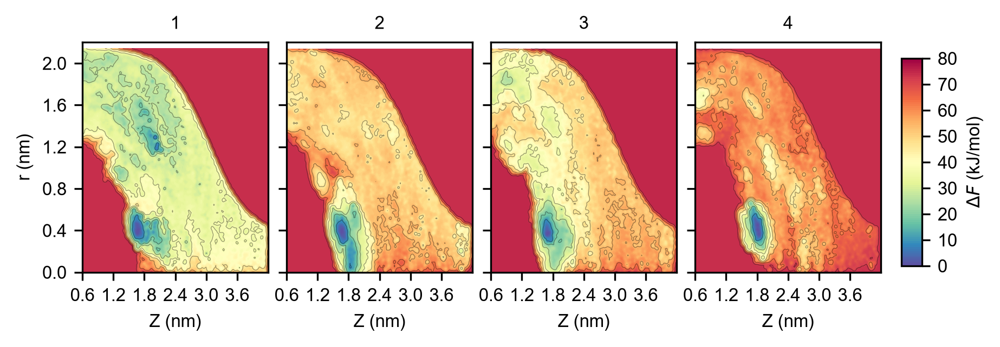

In [ ]:
# -----------------------------
# Data preparation
# -----------------------------

df = colvar.copy()
# df = df[df["Replica"] == 0]
df = df[df["time"] > 0]

var1 = "poa_d.proj"
var2 = "poa_d.ext"

T = 300
BETA = 1/(KB*T)


# -----------------------------
# Figure setup
# -----------------------------

fig, axes = plt.subplots(
    1, 4,
    figsize=(16*cm2inch, 5*cm2inch),
    dpi=300,
    sharex=True,
    sharey=True
)

fig.subplots_adjust(
    left=0.08,
    right=0.86,
    bottom=0.18,
    top=0.90,
    wspace=0.1
)


pp = None


# -----------------------------
# Calculate and plot FES
# -----------------------------

for i, ax in enumerate(axes):

    data = df[df["Repeat"] == i+1]

    bias = data["opes1.bias"].to_numpy()

    cv1 = data[var1].to_numpy()
    cv2 = data[var2].to_numpy()

    cv = np.vstack([cv1, cv2])


    # weights
    logweights = BETA * (bias - np.max(bias))
    w = np.exp(logweights)
    w /= np.sum(w)


    fes, grid, bounds, error = compute_fes(
        cv.T,
        weights=w,
        blocks=1,
        kbt=KB*T,
        bandwidth=0.005,
        scale_by="range",
        plot=False,
        plot_max_fes=100,
        eps=1e-10,
        backend="KDEpy",
    )


    extent = [item for sublist in bounds for item in sublist]


    pp = ax.contourf(
        fes,
        extent=extent,
        levels=np.linspace(0, 80,101),
        cmap="Spectral_r"
    )


    # contour lines
    ax.contour(
        fes,
        extent=extent,
        levels=np.linspace(0, 81, 10),
        colors="black",
        linewidths=0.3,
        alpha=0.4
    )

    ax.set_title(f"{i+1}",)

    ax.set_xlabel(r"Z (nm)", )

    if i == 0:
        ax.set_ylabel(r"r (nm)", )

    if i > 0:
        ax.tick_params(
            direction="out",
            top=False,
            left=True,
            right=False,
            # length=4,
            # width=1
        )


# -----------------------------
# Shared colorbar
# -----------------------------

cbar_ax = fig.add_axes([0.88, 0.20, 0.02, 0.65])

cbar = fig.colorbar(
    pp,
    cax=cbar_ax
)
cbar.set_ticks(np.linspace(0,80,9))


cbar.set_label(
    "$\Delta F$ (kJ/mol)",
)


# -----------------------------
# Axis limits
# -----------------------------

for ax in axes:
    ax.set_xlim(0.6, 4.2)
    ax.set_ylim(0, 2.2)
    ax.set_xticks(np.arange(0.6, 4.2, .6))
    ax.set_yticks(np.arange(0, 2.1, 0.4))

# -----------------------------
# Save figure
# -----------------------------

plt.savefig(
    "images/FB_2D_FES_disntaceRZ_all.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

### 2D FES from Reweighting distance R/Z FES

In [42]:
def plot_FES_and_scatter(data, colvar, 
                         var1,var2, 
                         bin1=100, bin2=100, 
                         level_min = 0, level_max = 20, 
                         step_n_lines = 20, 
                         step_n_colors = 20, 
                         
                         ax = None):
    bin1=bin1+1 
    bin2=bin2+1 
    alpha = np.array(data[var1]).reshape( bin1, bin2)
    comb_bonds = np.array(data[var2]).reshape( bin1, bin2)
    fes = np.array(data["file.free"]).reshape( bin1, bin2)
    fes = fes#*0.239006 #kJ to kkal
    #plot
    if ax != None:
        ax.contour(alpha, comb_bonds, fes, levels=np.linspace(level_min,level_max,step_n_lines), linewidths=0.5, colors='k')
        cntr = ax.contourf(alpha, comb_bonds, fes, levels=np.linspace(level_min,level_max, step_n_colors), cmap=cm.Spectral_r)

    else:
        plt.contour(alpha, comb_bonds, fes, levels=np.linspace(level_min,level_max,step_n_lines), linewidths=0.5, colors='k')
        cntr = plt.contourf(alpha, comb_bonds, fes, levels=np.linspace(level_min,level_max, step_n_colors), cmap=cm.Spectral_r)
                
        plt.colorbar(cntr, label="FES [kJ/mol]")
        plt.xlabel(var1)
        plt.ylabel(var2)
    
    # plt.show()
    return cntr

In [43]:
path_folding = r'C:/Users/vacaa/Documents/REPORTS/170/data/Folding_and_binding/OneOPES'

In [44]:
import subprocess
from pathlib import Path

script = Path("scripts") / "FES_from_Reweighting.py"
var1 = 'poa_d.proj'
var2 = 'poa_d.ext'
bin1=100
bin2=100


for i,folder_i in enumerate([1,2,3,4]):

    colvar = Path(path_folding) / str(folder_i) / "0" / "COLVAR.0"

    import sys

    cmd = [
        sys.executable,
        str(script),
        "--bias", "opes1.bias",
        "--colvar", str(colvar),
        "--outfile", f"FB_{folder_i}_FES_{var1}_{var2}",
        "--cv", f"{var1},{var2}",
        "--temp", "300",
        "-s", "0.0225,0.0125",
        "--bin", f"{bin1},{bin2}",
        "--blocks", "1",
        "--min", "0.0,0",
        "--max", "4.5,2.5",
    ]

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

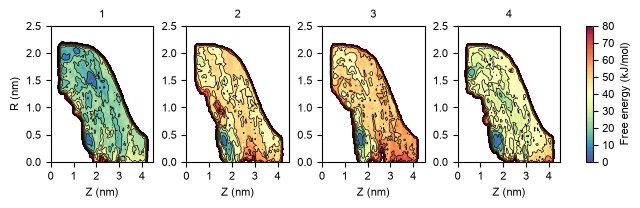

In [45]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(16*cm2inch, 5*cm2inch),
    constrained_layout=True,
)
for i, folder_i in enumerate([1, 2, 3, 4]):

    data = load_dataframe(f"FB_{folder_i}_FES_{var1}_{var2}")

    mappable = plot_FES_and_scatter(
        data,
        colvar,
        var1,
        var2,
        bin1=bin1,
        bin2=bin2,
        level_min=0,
        level_max=80,
        step_n_lines=10,
        step_n_colors=101,
        ax=axes[i],
    )

    axes[i].set_title(f"{i+1}")
    axes[i].set_xlabel("Z (nm)")

    if i == 0:
        axes[i].set_ylabel("R (nm)")

for ax in axes:
    ax.set_xlim(0, 4.5)
    ax.set_ylim(0.0, 2.5)
    ax.set_xticks(np.arange(0, 4.6, 1.0))
    ax.set_yticks(np.arange(0.0, 2.51, 0.5))
    ax.tick_params(direction="out")

# Shared colorbar

cbar = fig.colorbar(
    mappable,
    ax=axes,
    location="right",
)

cbar.set_label("Free energy (kJ/mol)")
cbar.set_ticks(np.arange(0, 81, 10))


plt.savefig(
    "images/FB_2D_FES_distanceRZ_reweighting.png",
    dpi=600,
)

plt.show()

### 2D FES from Reweighting distance cmapN/cmapF FES

In [46]:
script = Path("scripts") / "FES_from_Reweighting.py"
var1 = 'cmap_N_sum'
var2 = 'cmap_F_sum'
bin1=100
bin2=100


for i,folder_i in enumerate([1,2,3,4]):

    colvar = Path(path_folding) / str(folder_i) / "0" / "COLVAR.0"

    import sys

    cmd = [
        sys.executable,
        str(script),
        "--bias", "opes1.bias",
        "--colvar", str(colvar),
        "--outfile", f"FB_{folder_i}_FES_{var1}_{var2}",
        "--cv", f"{var1},{var2}",
        "--temp", "300",
        "-s", "0.005,0.005",
        "--bin", f"{bin1},{bin2}",
        "--blocks", "1",
        "--min", "0.0,0",
        "--max", "1.0,1.0",
    ]

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

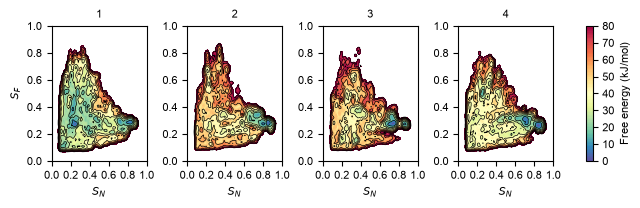

In [48]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(16*cm2inch, 5*cm2inch),
    constrained_layout=True,
)
for i, folder_i in enumerate([1, 2, 3, 4]):

    data = load_dataframe(f"FB_{folder_i}_FES_{var1}_{var2}")

    mappable = plot_FES_and_scatter(
        data,
        colvar,
        var1,
        var2,
        bin1=bin1,
        bin2=bin2,
        level_min=0,
        level_max=80,
        step_n_lines=10,
        step_n_colors=101,
        ax=axes[i],
    )

    axes[i].set_title(f"{i+1}")
    axes[i].set_xlabel(r"$S_{N}$", )

    if i == 0:
        axes[i].set_ylabel(r"$S_{F}$",)

for ax in axes:
    ax.set_xlim(0, 1.0)
    ax.set_ylim(0.0, 1.0)
    ax.set_xticks(np.arange(0, 1.01, 0.2))
    ax.set_yticks(np.arange(0.0, 1.01, 0.2))
    ax.tick_params(direction="out")

# Shared colorbar

cbar = fig.colorbar(
    mappable,
    ax=axes,
    location="right",
)

cbar.set_label("Free energy (kJ/mol)")
cbar.set_ticks(np.arange(0, 81, 10))


plt.savefig(
    "images/FB_2D_FES_cmapN_cmapF_reweighting.png",
    dpi=600,
)

plt.show()

### 2D FES from Reweighting distance alpha/cmapN FES

In [55]:
script = Path("scripts") / "FES_from_Reweighting.py"
var1 = 'cmap_N_sum'
var2 = 'alpha'
bin1=100
bin2=100


for i,folder_i in enumerate([1,2,3,4]):

    colvar = Path(path_folding) / str(folder_i) / "0" / "COLVAR.0"

    import sys

    cmd = [
        sys.executable,
        str(script),
        "--bias", "opes1.bias",
        "--colvar", str(colvar),
        "--outfile", f"FB_{folder_i}_FES_{var1}_{var2}",
        "--cv", f"{var1},{var2}",
        "--temp", "300",
        "-s", "0.005,0.005",
        "--bin", f"{bin1},{bin2}",
        "--blocks", "1",
        "--min", "0.0,0",
        "--max", "1.0,15.0",
    ]

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True
    )

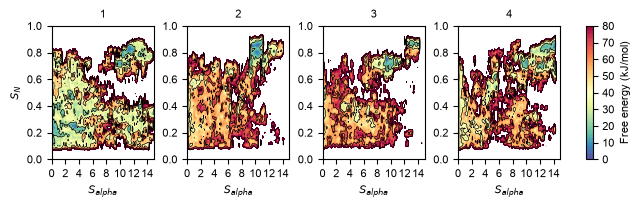

In [68]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(16*cm2inch, 5*cm2inch),
    constrained_layout=True,
)
for i, folder_i in enumerate([1, 2, 3, 4]):

    data = load_dataframe(f"FB_{folder_i}_FES_{var1}_{var2}")

    mappable = plot_FES_and_scatter(
        data,
        colvar,
        var2,
        var1,
        bin1=bin2,
        bin2=bin1,
        level_min=0,
        level_max=80,
        step_n_lines=5,
        step_n_colors=101,
        ax=axes[i],
    )

    axes[i].set_title(f"{i+1}")
    axes[i].set_xlabel(r"$S_{alpha}$", )

    if i == 0:
        axes[i].set_ylabel(r"$S_{N}$",)

for ax in axes:
    ax.set_xlim(0, 15.0)
    ax.set_ylim(0.0, 1.0)
    ax.set_xticks(np.arange(0, 15.1, 2))
    ax.set_yticks(np.arange(0.0, 1.01, 0.2))
    ax.tick_params(direction="out")

# Shared colorbar

cbar = fig.colorbar(
    mappable,
    ax=axes,
    location="right",
)

cbar.set_label("Free energy (kJ/mol)")
cbar.set_ticks(np.arange(0, 81, 10))


plt.savefig(
    "images/FB_2D_FES_alpha_cmapN_reweighting.png",
    dpi=600,
)

plt.show()

### Binding mechanism. Native state.

In [65]:
path_folding = r'C:\Users\vacaa\Documents\REPORTS\170\data\Folding_and_binding\OneOPES'
repeat, replica, stride = 4, 0, 50
state = 'N'

native_contacts_pairs = ['493-953','474-953','490-953','513-957','497-957','470-953','502-957','478-949','489-949','486-949','501-960','498-956','471-947','471-954','504-958']
flipped_contacts_pairs = ['474-960','490-961','490-960','490-957','513-949','497-953','513-953','498-954','510-959','504-948','504-945','498-947']

# C-map data
cmap = load_dataframe(
    f'{path_folding}/{repeat}/0/COLVAR_CMAP_RERUN'
).iloc[::].reset_index(drop=True)

if state=='N':
    contacts_pairs = native_contacts_pairs

    contact_columns = [
        c for c in cmap.columns
        if c.startswith("cmap_N")
    ]
elif state == 'F':
    contacts_pairs = flipped_contacts_pairs

    contact_columns = [
        c for c in cmap.columns
        if c.startswith("cmap_F")
    ]

# CV + bias data
df = colvar[
    (colvar["Repeat"] == repeat) &
    (colvar["Replica"] == replica)
].iloc[::stride].reset_index(drop=True)

if len(df) != len(cmap):
    raise ValueError(f"Frame mismatch: {len(df)} vs {len(cmap)}")

cmap_sum = df["cmap_N_sum"].to_numpy(float)
contacts = cmap[contact_columns].to_numpy(float)

# OPES weights
bias = df["opes1.bias"].to_numpy(float)
weights = np.exp(BETA * (bias - np.nanmax(bias)))

# Distance bins
bins = np.arange(0.5, 4.5, 0.25)
bins = np.arange(0.0, 1.0, 0.1)

contact_probabilities = np.full(
    (len(bins) - 1, len(contact_columns)), np.nan
)

for i, (lo, hi) in enumerate(zip(bins[:-1], bins[1:])):
    mask = (cmap_sum >= lo) & (cmap_sum < hi)
    if mask.any():
        w = weights[mask]
        contact_probabilities[i] = np.average(
            contacts[mask], axis=0, weights=w
        )
    print(f"cmap_N_sum = {lo:g}-{hi:g}: {mask.sum()} frames")

print("Shape:", contact_probabilities.shape)

cmap_N_sum = 0-0.1: 70 frames
cmap_N_sum = 0.1-0.2: 1233 frames
cmap_N_sum = 0.2-0.3: 1115 frames
cmap_N_sum = 0.3-0.4: 902 frames
cmap_N_sum = 0.4-0.5: 758 frames
cmap_N_sum = 0.5-0.6: 438 frames
cmap_N_sum = 0.6-0.7: 253 frames
cmap_N_sum = 0.7-0.8: 136 frames
cmap_N_sum = 0.8-0.9: 96 frames
Shape: (9, 15)


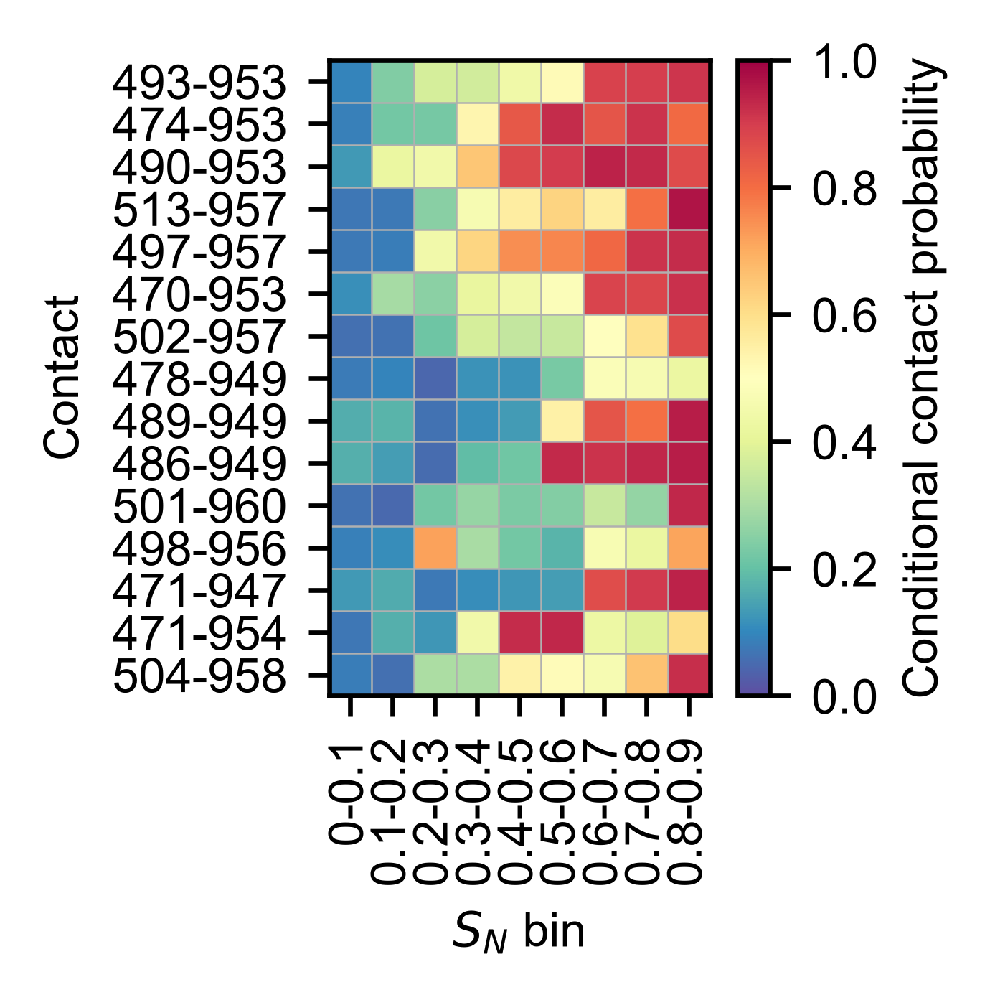

In [66]:
fig, ax = plt.subplots(
    figsize=(9 * cm2inch, 6 * cm2inch),
    dpi=600
)

im = ax.imshow(
    contact_probabilities.T,
    cmap="Spectral_r",
    vmin=0,
    vmax=1,
    aspect="equal",
    interpolation="nearest"
)

# ------------------------------------------------------------
# Grid lines between cells
# ------------------------------------------------------------

ax.set_xticks(
    np.arange(-0.5, len(bins) - 1, 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, len(contact_columns), 1),
    minor=True
)

ax.grid(
    which="minor",
    linewidth=0.3
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# ------------------------------------------------------------
# Tick labels
# ------------------------------------------------------------

ax.set_xticks(
    np.arange(len(bins) - 1)
)

ax.set_xticklabels(
    [f"{lo:g}-{hi:g}" for lo, hi in zip(bins[:-1], bins[1:])],
    rotation=90
)

ax.set_yticks(
    np.arange(len(contact_columns))
)

ax.set_yticklabels(
    contacts_pairs
)

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel(r"Z bin, nm")
ax.set_xlabel(r"$S_{N}$ bin")
ax.set_ylabel("Contact")

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    pad=0.02
)

cbar.set_label(
    "Conditional contact probability"
)

cbar.set_ticks(
    np.arange(0, 1.01, 0.2)
)

cbar.outline.set_edgecolor("black")
cbar.outline.set_linewidth(0.8)

# ------------------------------------------------------------

plt.tight_layout()

plt.savefig(
    f"images/FB_Binned_N_contact_probability_along_cmap_N_sum_OPES_repeat_{repeat}.png",
    dpi=600,
)

plt.show()

### OneOPES FCP1term folding mechanism along alpha

In [28]:
repeat = 4


traj = md.load(
        f"{path_folding}/{repeat}/0/md_0_2.xtc",
        top=f"{path_folding}/{repeat}/0/1onv_pbc.pdb"
    )



# Keep only protein atoms
protein_idx = traj.topology.select("chainid 1")

residue_labels = [
    f"{res.name}{res.resSeq}"
    for res in traj.topology.residues
    if res.chain.index == 1
]

traj_protein = traj.atom_slice(protein_idx)

# Compute DSSP on the protein only
dssp = md.compute_dssp(traj_protein)

# Count all helix types (H = α, G = 3₁₀, I = π)
helix = np.isin(dssp, ["H", "G", "I"])


# ============================================================
# Sort trajectory by alpha
# ============================================================
alpha = colvar.loc[
    (colvar["Repeat"] == repeat) &
    (colvar["Replica"] == 0),
    "alpha"
].to_numpy(dtype=float)[::50]

# Sort frame indices by alpha
sort_idx = np.argsort(alpha)

# Reorder all frame-dependent quantities
alpha_sorted = alpha[sort_idx]
helix_sorted = helix[sort_idx]

# ============================================================
# Weights
# ============================================================

bias = colvar.loc[
    colvar["Repeat"] == repeat,
    "opes1.bias"
].to_numpy(dtype=float)[::50]

logweights = BETA * (bias - np.max(bias))
weights = np.exp(logweights)
weights /= np.sum(weights)

weights_sorted = weights[sort_idx]


# ============================================================
# Calculate helix probability in alpha bins
# ============================================================

alpha_min = 0
alpha_max = 15

alpha_bins = np.arange(
    alpha_min,
    alpha_max + 1,
    1
)

helix_probabilities = []

for i in range(15):

    # Frames with:
    # i <= alpha < i+1
    mask = (
        (alpha_sorted >= i) &
        (alpha_sorted < i + 1)
    )

    print(
        f"alpha = {i}-{i+1}: "
        f"{mask.sum()} frames"
    )

    # Select frames
    helix_group = helix_sorted[mask]
    weights_group = weights_sorted[mask]

    # Check that the bin contains frames
    if mask.sum() == 0:

        # No data in this alpha interval
        helix_probability = np.full(
            helix.shape[1],
            np.nan
        )

    else:

        # Normalize weights within this alpha bin to have a conditional probability
        weights_group = weights_group / weights_group.sum()
        
        # Weighted helix probability per residue
        helix_probability = np.average(
            helix_group.astype(float),
            axis=0,
            weights=None
        )

    helix_probabilities.append(
        helix_probability
    )


# Convert to 2D array
helix_probabilities = np.array(
    helix_probabilities
)

print(
    "Shape:",
    helix_probabilities.shape
)

alpha = 0-1: 2653 frames
alpha = 1-2: 333 frames
alpha = 2-3: 322 frames
alpha = 3-4: 302 frames
alpha = 4-5: 272 frames
alpha = 5-6: 108 frames
alpha = 6-7: 53 frames
alpha = 7-8: 112 frames
alpha = 8-9: 201 frames
alpha = 9-10: 187 frames
alpha = 10-11: 152 frames
alpha = 11-12: 122 frames
alpha = 12-13: 86 frames
alpha = 13-14: 54 frames
alpha = 14-15: 44 frames
Shape: (15, 21)


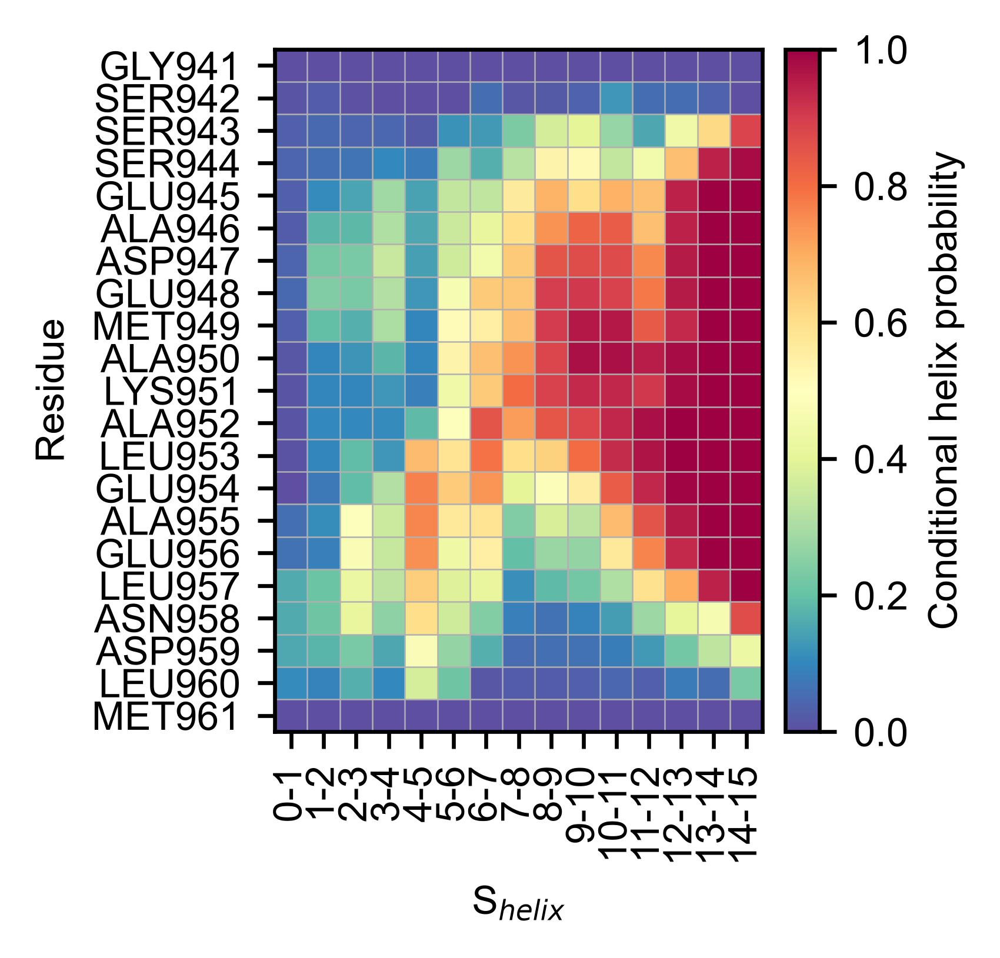

In [29]:
fig, ax = plt.subplots(
    figsize=(9 * cm2inch, 7 * cm2inch),
    dpi=600
)

im = ax.imshow(
    helix_probabilities.T,
    cmap="Spectral_r",
    vmin=0,
    vmax=1,
    aspect="equal",
    interpolation="nearest"
)

# ------------------------------------------------------------
# Grid lines between cells
# ------------------------------------------------------------

ax.set_xticks(np.arange(-0.5, 15, 1), minor=True)
ax.set_yticks(
    np.arange(-0.5, len(residue_labels), 1),
    minor=True
)

ax.grid(
    which="minor",
    linewidth=0.3
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# ------------------------------------------------------------
# Tick labels
# ------------------------------------------------------------

ax.set_xticks(np.arange(15))
ax.set_xticklabels(
    [f"{i}-{i+1}" for i in range(15)],
    rotation=90
)

ax.set_yticks(np.arange(len(residue_labels)))
ax.set_yticklabels(residue_labels)

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel("S$_{helix}$")
ax.set_ylabel("Residue")

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    pad=0.02
)

cbar.set_label("Conditional helix probability")
cbar.set_ticks(np.arange(0,1.01,0.2))

cbar.outline.set_edgecolor("black")
cbar.outline.set_linewidth(0.8)

# ------------------------------------------------------------

plt.tight_layout()

plt.savefig(
    f"images/FB_Binned_helix_probability_along_alpha_OPES_repeat_{repeat}.png",
    dpi=600,
)

plt.show()

### OneOPES FCP1term folding mechanism along CMAP_N

In [52]:

bias, cmap_N

(array([-40.      , -40.      , -40.      , ...,  36.092708, -26.255919,
        -30.764219], shape=(40001,)),
 array([0.818788, 0.809487, 0.813139, ..., 0.419667, 0.390994, 0.400872],
       shape=(5001,)))

In [55]:
repeat = 1


traj = md.load(
        f"{path_folding}/{repeat}/0/md_0_2.xtc",
        top=f"{path_folding}/{repeat}/0/1onv_pbc.pdb"
    )



# Keep only protein atoms
protein_idx = traj.topology.select("chainid 1")

residue_labels = [
    f"{res.name}{res.resSeq}"
    for res in traj.topology.residues
    if res.chain.index == 1
]

traj_protein = traj.atom_slice(protein_idx)

# Compute DSSP on the protein only
dssp = md.compute_dssp(traj_protein)

# Count all helix types (H = α, G = 3₁₀, I = π)
helix = np.isin(dssp, ["H", "G", "I"])


# ============================================================
# Sort trajectory by alpha
# ============================================================
cmap_N = colvar.loc[
    (colvar["Repeat"] == repeat) &
    (colvar["Replica"] == 0),
    "cmap_N_sum"
].to_numpy(dtype=float)[::50]

# Sort frame indices by alpha
sort_idx = np.argsort(cmap_N)

# Reorder all frame-dependent quantities
cmap_N_sorted = cmap_N[sort_idx]
helix_sorted = helix[sort_idx]

# ============================================================
# Weights
# ============================================================

bias = colvar.loc[
    (colvar["Repeat"] == repeat) &
    (colvar["Replica"] == 0),
    "opes1.bias"
].to_numpy(dtype=float)[::50]

logweights = BETA * (bias - np.max(bias))
weights = np.exp(logweights)
weights /= np.sum(weights)

weights_sorted = weights[sort_idx]


# ============================================================
# Calculate helix probability in alpha bins
# ============================================================

cmap_N_min = 0
cmap_N_max = 0.9

cmap_N_bins = np.arange(
    cmap_N_min,
    cmap_N_max + 0.1,
    0.1
)

helix_probabilities = []

for i,_ in enumerate(cmap_N_bins[:-1]):

    # Frames with:
    # i <= alpha < i+1
    mask = (
        (cmap_N_sorted >= cmap_N_bins[i]) &
        (cmap_N_sorted < cmap_N_bins[i + 1])
    )

    print(
        f"cmap N = {cmap_N_bins[i]}-{cmap_N_bins[i + 1]}: "
        f"{mask.sum()} frames"
    )

    # Select frames
    helix_group = helix_sorted[mask]
    weights_group = weights_sorted[mask]

    # Check that the bin contains frames
    if mask.sum() == 0:

        # No data in this alpha interval
        helix_probability = np.full(
            helix.shape[1],
            np.nan
        )

    else:

        # Normalize weights within this alpha bin to have a conditional probability
        weights_group = weights_group / weights_group.sum()
        
        # Weighted helix probability per residue
        helix_probability = np.average(
            helix_group.astype(float),
            axis=0,
            weights=None
        )

    helix_probabilities.append(
        helix_probability
    )


# Convert to 2D array
helix_probabilities = np.array(
    helix_probabilities
)

print(
    "Shape:",
    helix_probabilities.shape
)

cmap N = 0.0-0.1: 43 frames
cmap N = 0.1-0.2: 1290 frames
cmap N = 0.2-0.30000000000000004: 1271 frames
cmap N = 0.30000000000000004-0.4: 1037 frames
cmap N = 0.4-0.5: 598 frames
cmap N = 0.5-0.6000000000000001: 377 frames
cmap N = 0.6000000000000001-0.7000000000000001: 195 frames
cmap N = 0.7000000000000001-0.8: 144 frames
cmap N = 0.8-0.9: 46 frames
Shape: (9, 21)


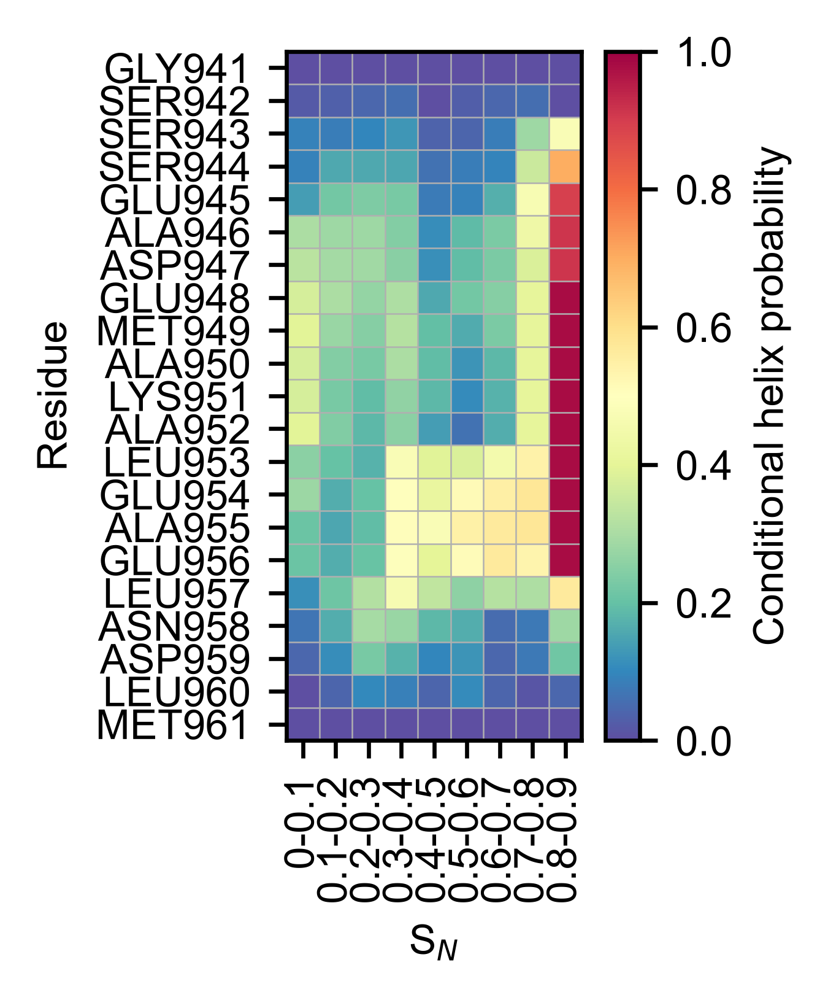

In [56]:
fig, ax = plt.subplots(
    figsize=(9 * cm2inch, 7 * cm2inch),
    dpi=600
)

im = ax.imshow(
    helix_probabilities.T,
    cmap="Spectral_r",
    vmin=0,
    vmax=1,
    aspect="equal",
    interpolation="nearest"
)

# ------------------------------------------------------------
# Grid lines between cells
# ------------------------------------------------------------
ax.set_xticks(
    np.arange(-0.5, len(cmap_N_bins) - 1, 1),
    minor=True
)
ax.set_yticks(
    np.arange(-0.5, len(residue_labels), 1),
    minor=True
)

ax.grid(
    which="minor",
    linewidth=0.3
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# ------------------------------------------------------------
# Tick labels
# ------------------------------------------------------------

ax.set_xticks(
    np.arange(len(cmap_N_bins) - 1)
)

ax.set_xticklabels(
    [f"{lo:g}-{hi:g}" for lo, hi in zip(cmap_N_bins[:-1], cmap_N_bins[1:])],
    rotation=90
)
ax.set_yticks(np.arange(len(residue_labels)))
ax.set_yticklabels(residue_labels)

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel("S$_{N}$")
ax.set_ylabel("Residue")

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    pad=0.02
)

cbar.set_label("Conditional helix probability")
cbar.set_ticks(np.arange(0,1.01,0.2))

cbar.outline.set_edgecolor("black")
cbar.outline.set_linewidth(0.8)

# ------------------------------------------------------------

plt.tight_layout()

plt.savefig(
    f"images/FB_Binned_helix_probability_along_cmap_N_OPES_repeat_{repeat}.png",
    dpi=600,
)

plt.show()